# Exploratory Data Analysis: Family Background and Adult Outcomes

This notebook combines the team's work on the two primary datasets (PSID and NLSY97) and the two secondary datasets (Opportunity Insights and ELS).

## Part 1: Primary datasets, cleaning, and NLSY97 analysis

In [1]:
import polars as pl
from pathlib import Path

psid = pl.read_csv("data/raw/psid/J365605.csv")
psid_linkage = pl.read_csv("data/raw/psid/M365605.csv")
nlsy97 = pl.read_csv("data/raw/nlsy97/NLSY97_expanded.csv")

for name, df in [
    ("PSID", psid),
    ("PSID linkage", psid_linkage),
    ("NLSY97", nlsy97),
]:
    print(f"{name}: {df.shape}")

PSID: (2362, 25)
PSID linkage: (21511, 116)
NLSY97: (8984, 12)


In [2]:
for name, df in [
    ("PSID", psid),
    ("PSID linkage", psid_linkage),
    ("NLSY97", nlsy97),
]:
    print(f"\n--- {name} ---")

    print("Shape:", df.shape)

    print("\nColumn names and data types:")
    df.glimpse()

    print("\nMissing values:")
    display(df.null_count())

    print("\nSummary statistics:")
    display(df.describe())


--- PSID ---
Shape: (2362, 25)

Column names and data types:
Rows: 2362
Columns: 25
$ TAS      <i64> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1
$ TAS21    <i64> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1
$ ER30000  <i64> 2, 2, 2, 2, 2, 2, 2, 2, 2, 2
$ ER30001  <i64> 4, 4, 5, 7, 7, 7, 7, 7, 7, 7
$ ER30002  <i64> 42, 44, 33, 46, 47, 48, 49, 50, 51, 52
$ ER32000  <i64> 1, 2, 1, 2, 2, 2, 2, 1, 2, 2
$ ER32006  <i64> 2, 2, 2, 2, 2, 2, 2, 2, 2, 2
$ ER10001  <i64> 7, null, 7, 7, 7, 7, 7, 7, 7, 7
$ ER12079  <f64> 7512.0, null, 46473.03, 14000.0, 14000.0, 14000.0, 58200.0, 11400.0, 14000.0, 11400.0
$ ER12222  <i64> 12, null, 10, 11, 11, 11, 12, 10, 11, 10
$ ER12223  <i64> 0, null, 12, 0, 0, 0, 12, 11, 0, 11
$ ER33401  <i64> 4246, 0, 3633, 5107, 5107, 5107, 1910, 1111, 5107, 1111
$ ER33402  <i64> 3, 0, 5, 2, 4, 5, 0, 0, 0, 0
$ ER33403  <i64> 30, 0, 30, 30, 30, 30, 0, 0, 0, 0
$ ER34901  <i64> 7535, 3753, 4065, 6614, 4476, 4239, 6528, 4020, 6582, 4020
$ ER34902  <i64> 1, 2, 1, 2, 2, 1, 2, 2, 2, 3
$ ER34903  <i64> 10, 30, 10,

TAS,TAS21,ER30000,ER30001,ER30002,ER32000,ER32006,ER10001,ER12079,ER12222,ER12223,ER33401,ER33402,ER33403,ER34901,ER34902,ER34903,TA210001,TA210002,TA210003,TA210004,TA210220,TA210225,TA210678,TA210679
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,206,206,206,206,0,0,0,0,0,0,0,0,0,0,0,0,0,0



Summary statistics:


statistic,TAS,TAS21,ER30000,ER30001,ER30002,ER32000,ER32006,ER10001,ER12079,ER12222,ER12223,ER33401,ER33402,ER33403,ER34901,ER34902,ER34903,TA210001,TA210002,TA210003,TA210004,TA210220,TA210225,TA210678,TA210679
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",2362.0,2362.0,2362.0,2362.0,2362.0,2362.0,2362.0,2156.0,2156.0,2156.0,2156.0,2362.0,2362.0,2362.0,2362.0,2362.0,2362.0,2362.0,2362.0,2362.0,2362.0,2362.0,2362.0,2362.0,2362.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,206.0,206.0,206.0,206.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",1.0,1.0,2.0,3439.245131,50.563082,1.528789,2.005927,7.0,39188.625867,16.408163,11.196197,3657.917866,1.511008,11.631668,5063.024132,6.223539,24.207875,1.0,1183.27011,5063.024132,6.223539,4.753175,30.798476,2.324301,527758.147756
"""std""",0.0,0.0,0.0,2121.752279,48.114227,0.499276,0.44708,0.0,34668.273046,18.640609,18.432192,2769.325304,4.105152,17.45807,2502.924305,13.534588,11.550103,0.0,683.70514,2502.924305,13.534588,13.646488,22.478943,1.998049,2.2016e6
"""min""",1.0,1.0,2.0,4.0,1.0,1.0,1.0,7.0,-64500.0,0.0,0.0,0.0,0.0,0.0,19.0,1.0,10.0,1.0,1.0,19.0,1.0,1.0,0.0,1.0,0.0
"""25%""",1.0,1.0,2.0,1583.0,33.0,1.0,2.0,7.0,16212.0,11.0,0.0,1421.0,0.0,0.0,3044.0,1.0,10.0,1.0,591.0,3044.0,1.0,1.0,0.0,1.0,0.0
"""50%""",1.0,1.0,2.0,3111.0,37.0,2.0,2.0,7.0,29600.0,12.0,11.0,3515.0,0.0,0.0,5302.0,2.0,30.0,1.0,1183.0,5302.0,2.0,1.0,40.0,1.0,9953.0
"""75%""",1.0,1.0,2.0,5573.0,45.0,2.0,2.0,7.0,53500.0,15.0,14.0,5195.0,3.0,30.0,7328.0,3.0,30.0,1.0,1776.0,7328.0,3.0,6.0,52.0,5.0,30000.0
"""max""",1.0,1.0,2.0,6867.0,251.0,2.0,4.0,7.0,386250.0,99.0,99.0,10442.0,74.0,97.0,9243.0,52.0,98.0,1.0,2367.0,9243.0,52.0,99.0,52.0,9.0,9.999999e6



--- PSID linkage ---
Shape: (21511, 116)

Column names and data types:
Rows: 21511
Columns: 116
$ CDSCUMREL  <i64> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1
$ CDSCUMID68 <i64> 4, 4, 4, 4, 4, 4, 4, 4, 4, 4
$ CDSCUMPN   <i64> 3, 5, 7, 31, 36, 37, 38, 39, 41, 42
$ CDSTYPE97  <i64> 3, 2, 2, 2, 2, 1, 1, 1, 1, 1
$ CRFID97    <i64> 3854, 3853, 5491, 4246, 5490, 4773, 5491, 3854, 4246, 4246
$ CRSN97     <i64> 1, 2, 1, 1, 2, 3, 2, 4, 2, 3
$ CDS_HID97  <i64> 922, 0, 0, 1022, 0, 0, 0, 922, 1022, 1022
$ CDS_SN97   <i64> 0, 0, 0, 1, 0, 0, 0, 0, 0, 0
$ ID68PCG97  <i64> 0, 0, 0, 0, 0, 4, 4, 4, 4, 4
$ PNPCG97    <i64> 0, 0, 0, 0, 0, 179, 7, 173, 31, 31
$ CRPCGFID97 <i64> 0, 0, 0, 0, 0, 4773, 5491, 3854, 4246, 4246
$ CRPCGSN97  <i64> 0, 0, 0, 0, 0, 1, 1, 2, 1, 1
$ ID68OCG97  <i64> 0, 0, 0, 0, 0, 0, 0, 4, 0, 0
$ PNOCG97    <i64> 0, 0, 0, 0, 0, 0, 0, 3, 0, 0
$ CROCGFID97 <i64> 0, 0, 0, 0, 0, 0, 0, 3854, 0, 0
$ CROCGSN97  <i64> 0, 0, 0, 0, 0, 0, 0, 1, 0, 0
$ DEMOG_97   <i64> 0, 0, 0, 0, 0, 1, 1, 1, 1, 1
$ PCGHH_97   

...

statistic,CDSCUMREL,CDSCUMID68,CDSCUMPN,CDSTYPE97,CRFID97,CRSN97,CDS_HID97,CDS_SN97,ID68PCG97,PNPCG97,CRPCGFID97,CRPCGSN97,ID68OCG97,PNOCG97,CROCGFID97,CROCGSN97,DEMOG_97,PCGHH_97,PCGCH_97,CHILD_97,CDSTYPE02,CRFID02,CRSN02,CDS_HID02,CDS_SN02,ID68PCG02,PNPCG02,CRPCGFID02,CRPCGSN02,ID68OCG02,PNOCG02,CROCGFID02,CROCGSN02,DEMOG_02,PCGHH_02,PCGCH_02,…,PCGHHNO19,DEMOG_19,PCGHH_19,PCGCH_19,CHILD_19,PCGHH_20,PCGCH_20,CDSTYPE21,CRFID21,CRSN21,CDS_HID21,CDS_SN21,ID68PCG21,PNPCG21,CRPCGFID21,CRPCGSN21,CDSPCGSN21,PCGHHNO21,DEMOG_21,PCGHH_21,PCGCH_21,CHILD_21,CDSTYPE24,CRFID24,CRSN24,CDS_HID24,CDS_SN24,ID68PCG24,PNPCG24,CRPCGFID24,CRPCGSN24,CDSPCGSN24,PCGHHNO24,DEMOG_24,PCGHH_24,PCGCH_24,CHILD_24
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,…,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",1.0,3303.368277,67.548185,0.711775,3586.183859,1.439264,168.983869,0.072475,550.785087,11.684115,633.452931,0.291014,335.324811,10.047464,453.410627,0.142625,0.165636,0.071405,0.165636,0.103342,0.576821,3623.256613,1.908698,283.478825,0.093812,445.915392,9.593836,518.068244,0.226256,253.10139,8.393148,326.438706,0.119799,0.13514,0.093348,0.13514,…,0.342662,0.215192,0.121612,0.214541,0.07359,0.0536,0.092836,0.471666,3572.823765,3.32588,8070.126075,0.536098,418.845474,9.227697,518.749152,0.188415,0.186788,0.197852,0.120404,0.073265,0.120404,0.034819,0.715866,3506.509832,3.407791,12360.45135,0.83111,660.098647,14.876435,877.95328,0.304914,0.284506,0.301334,0.190228,0.106969,0.189252,0.054298
"""std""",0.0,2131.413257,72.820843,1.085105,2726.576401,4.232418,376.528991,0.26337,1525.000989,41.730246,1787.347339,0.695681,1162.572794,39.942417,1572.065236,1.142974,0.371762,0.257507,0.371762,0.304413,1.009826,2239.140349,6.576421,542.316199,0.293165,1387.598519,40.423918,1504.44782,0.766324,1013.163469,36.887113,1202.714335,1.144759,0.341881,0.290926,0.341881,…,0.477345,0.410965,0.326845,0.410513,0.261109,0.225233,0.29021,1.039358,3079.326771,10.138955,16260.720989,1.229608,1334.132406,36.559674,1607.094565,0.534072,0.52997,0.398856,0.32544,0.260577,0.32544,0.183326,1.164391,3094.782839,10.284757,18892.452468,1.515876,1635.743304,45.246628,2101.819335,1.213228,0.635346,0.462079,0.39249,0.30908,0.391718,0.22661
"""min""",1.0,4.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""25%""",1.0,1475.0,31.0,0.0,1426.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1767.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""50%""",1.0,2782.0,38.0,0.0,3368.0,0.0,0.0,0


--- NLSY97 ---
Shape: (8984, 12)

Column names and data types:
Rows: 8984
Columns: 12
$ R0000100 <i64> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10
$ R0536300 <i64> 2, 1, 2, 2, 1, 2, 1, 2, 1, 1
$ R0536401 <i64> 9, 7, 9, 2, 10, 1, 4, 6, 10, 3
$ R0536402 <i64> 1981, 1982, 1983, 1981, 1982, 1982, 1983, 1981, 1982, 1984
$ R1204500 <i64> -3, -4, 63000, 11700, -3, -3, -3, -3, -3, -3
$ R1235800 <i64> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1
$ R1302400 <i64> 16, 17, -3, 12, 12, -3, -3, 6, 6, 6
$ R1302500 <i64> 8, 15, 12, 12, 12, 12, 12, 12, 12, 12
$ R1482600 <i64> 4, 2, 2, 2, 2, 2, 2, 4, 4, 4
$ U5753300 <i64> -5, 1, 0, 1, 1, 1, -5, 1, 1, 1
$ U5753500 <i64> -5, 115000, -4, 45000, 150000, 25000, -5, 70000, 120000, 135000
$ Z9061911 <i64> 0, 52, 0, 52, 52, 52, -4, 51, 52, 52


Missing values:


R0000100,R0536300,R0536401,R0536402,R1204500,R1235800,R1302400,R1302500,R1482600,U5753300,U5753500,Z9061911
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0,0



Summary statistics:


statistic,R0000100,R0536300,R0536401,R0536402,R1204500,R1235800,R1302400,R1302500,R1482600,U5753300,U5753500,Z9061911
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",8984.0,8984.0,8984.0,8984.0,8984.0,8984.0,8984.0,8984.0,8984.0,8984.0,8984.0,8984.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",4504.301759,1.48809,6.555988,1982.010352,33996.298753,0.751113,9.347952,11.292631,2.787845,-0.659728,36405.141696,30.649488
"""std""",2603.135871,0.499886,3.469429,1.39687,41506.81987,0.432392,7.504797,5.469229,1.313645,2.550847,54970.030437,25.044463
"""min""",1.0,1.0,1.0,1980.0,-48100.0,0.0,-4.0,-4.0,1.0,-5.0,-5.0,-4.0
"""25%""",2249.0,1.0,3.0,1981.0,-3.0,1.0,6.0,11.0,1.0,-5.0,-5.0,0.0
"""50%""",4502.0,1.0,7.0,1982.0,23100.0,1.0,12.0,12.0,4.0,1.0,18000.0,51.0
"""75%""",6758.0,2.0,10.0,1983.0,51400.0,1.0,14.0,14.0,4.0,1.0,55000.0,52.0
"""max""",9022.0,2.0,12.0,1984.0,246474.0,1.0,95.0,95.0,4.0,1.0,380288.0,52.0


In [3]:
for column, count in psid.null_count().row(0, named=True).items():
    if count > 0:
        print(f"{column}: {count} missing values")

ER10001: 206 missing values
ER12079: 206 missing values
ER12222: 206 missing values
ER12223: 206 missing values


### PSID observations

The PSID dataset has 2,362 rows and 25 columns. Each row represents
a person. Most columns contain whole numbers, while family income
contains decimal values.

Four columns each have 206 missing values, which is about 8.7%
of the dataset. These columns are the data release number,
family income, household-head education, and spouse education.

The missing income and education values reduce the number of
people we can include in comparisons. We kept the original data
and created a cleaned copy for analysis. Rows with missing values
will be excluded only from comparisons that need those values.

In [4]:
display(
    psid.select(
        "ER12079",   # Family income
        "ER12222",   # Household-head education
        "ER12223",   # Spouse education
        "TA210679"   # Adult wages/salary
    ).describe()
)

statistic,ER12079,ER12222,ER12223,TA210679
str,f64,f64,f64,f64
"""count""",2156.0,2156.0,2156.0,2362.0
"""null_count""",206.0,206.0,206.0,0.0
"""mean""",39188.625867,16.408163,11.196197,527758.147756
"""std""",34668.273046,18.640609,18.432192,2.2016e6
"""min""",-64500.0,0.0,0.0,0.0
"""25%""",16212.0,11.0,0.0,0.0
"""50%""",29600.0,12.0,11.0,9953.0
"""75%""",53500.0,15.0,14.0,30000.0
"""max""",386250.0,99.0,99.0,9.999999e6


### Unusual values in PSID

Some values need to be handled before making comparisons.
Both education columns include 99, which means the answer is
missing or unknown. The wages column also includes 9,999,999
as a missing or unknown code. These codes make the averages
misleading, so we will treat them as missing values in our analysis.

The lowest family income is -$64,500. According to the codebook,
negative income can happen because of business or farm losses,
so we will keep this value.

In [5]:
psid.select(
    (pl.col("ER12222") == 99).sum().alias("head_education_unknown"),
    (pl.col("ER12223") == 99).sum().alias("spouse_education_unknown"),
    (pl.col("TA210679") == 9999999).sum().alias("wages_unknown"),
    (pl.col("ER12079") < 0).sum().alias("negative_family_income")
)

head_education_unknown,spouse_education_unknown,wages_unknown,negative_family_income
u32,u32,u32,u32
102,80,121,1


### PSID anomaly counts

| Issue | Rows affected | How we handled it |
|---|---:|---|
| Head education is coded as 99 | 102 | Treated as missing |
| Spouse education is coded as 99 | 80 | Treated as missing |
| Wages are coded as 9,999,999 | 121 | Treated as missing |
| Family income is negative | 1 | Kept because the codebook allows income losses |

In [6]:
psid_clean = psid.with_columns(
    pl.when(pl.col(column) == unknown_code)
    .then(None)
    .otherwise(pl.col(column))
    .alias(column)
    for column, unknown_code in [
        ("ER12222", 99),
        ("ER12223", 99),
        ("TA210679", 9999999),
    ]
)

In [7]:
for name, df in [
    ("PSID", psid),
    ("PSID linkage", psid_linkage),
    ("NLSY97", nlsy97),
]:
    duplicates = df.height - df.unique().height
    print(f"{name}: {duplicates} duplicate rows")

PSID: 0 duplicate rows
PSID linkage: 0 duplicate rows
NLSY97: 0 duplicate rows


### Duplicate rows

We checked the PSID, PSID linkage, and NLSY97 files for
duplicate rows. All three had 0 duplicates, so we did not remove
any rows.

In [8]:
for name, df in [
    ("PSID linkage", psid_linkage),
    ("NLSY97", nlsy97),
]:
    print(f"\n{name}:")
    missing = df.null_count().row(0, named=True)

    for column, count in missing.items():
        if count > 0:
            print(f"{column}: {count} missing values")

    if all(count == 0 for count in missing.values()):
        print("No null values found.")


PSID linkage:
No null values found.

NLSY97:
No null values found.


### Missing values in the other files

We found no null values in the raw PSID linkage or NLSY97 files.
However, NLSY97 uses negative codes for missing answers and skips.
We identified these codes and handled them in the cleaned copy.

In [9]:
print(nlsy97.columns)
display(nlsy97.describe())

['R0000100', 'R0536300', 'R0536401', 'R0536402', 'R1204500', 'R1235800', 'R1302400', 'R1302500', 'R1482600', 'U5753300', 'U5753500', 'Z9061911']


statistic,R0000100,R0536300,R0536401,R0536402,R1204500,R1235800,R1302400,R1302500,R1482600,U5753300,U5753500,Z9061911
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",8984.0,8984.0,8984.0,8984.0,8984.0,8984.0,8984.0,8984.0,8984.0,8984.0,8984.0,8984.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",4504.301759,1.48809,6.555988,1982.010352,33996.298753,0.751113,9.347952,11.292631,2.787845,-0.659728,36405.141696,30.649488
"""std""",2603.135871,0.499886,3.469429,1.39687,41506.81987,0.432392,7.504797,5.469229,1.313645,2.550847,54970.030437,25.044463
"""min""",1.0,1.0,1.0,1980.0,-48100.0,0.0,-4.0,-4.0,1.0,-5.0,-5.0,-4.0
"""25%""",2249.0,1.0,3.0,1981.0,-3.0,1.0,6.0,11.0,1.0,-5.0,-5.0,0.0
"""50%""",4502.0,1.0,7.0,1982.0,23100.0,1.0,12.0,12.0,4.0,1.0,18000.0,51.0
"""75%""",6758.0,2.0,10.0,1983.0,51400.0,1.0,14.0,14.0,4.0,1.0,55000.0,52.0
"""max""",9022.0,2.0,12.0,1984.0,246474.0,1.0,95.0,95.0,4.0,1.0,380288.0,52.0


### NLSY97 observations

The expanded NLSY97 dataset has 8,984 rows and 12 columns.
We added household income, both parents’ education, 2020 job
income, and weeks worked in 2020. These variables will help us
explore how family background relates to adult outcomes.

In [10]:
columns = [
    "R1204500",  # Household income
    "R1302400",  # Father's education
    "R1302500",  # Mother's education
    "U5753300",  # Received job income
    "U5753500",  # Wages/salary
    "Z9061911",  # Weeks worked
]

for column in columns:
    print(f"\n{column}:")
    display(
        nlsy97.filter(pl.col(column) < 0)
        .group_by(column)
        .len()
        .sort(column)
    )


R1204500:


R1204500,len
i64,u32
-48100,1
-8050,1
-7500,1
-4,938
-3,1458



R1302400:


R1302400,len
i64,u32
-4,668
-3,1188



R1302500:


...

U5753300,len
i64,u32
-5,2271
-3,1
-2,9
-1,46



U5753500:


U5753500,len
i64,u32
-5,2271
-4,1213
-2,224
-1,75



Z9061911:


Z9061911,len
i64,u32
-4,1621
-3,125


### NLSY97 missing and skip codes

Some missing answers are stored as negative codes instead of nulls.

| Variable | Rows with missing or skip codes |
|---|---:|
| Household income | 2,396 |
| Father’s education | 1,856 |
| Mother’s education | 688 |
| Received job income | 2,327 |
| Wages/salary | 3,783 |
| Weeks worked | 1,746 |

We replaced missing-response codes with nulls. For wages, we
changed skipped amounts to zero only when the respondent reported
receiving no job income. Other missing amounts stayed null.

We checked the codebook and kept the three negative household
income amounts because they are valid monetary values.

The table shows counts before cleaning. It does not include
education code 95, which we handled separately.

### NLSY97 cleaning decisions

We kept the three valid negative household income amounts and
replaced missing-response codes (-1 through -5) with nulls.

Education code 95 means “ungraded.” We excluded these values
from numeric education comparisons: 8 father records and
6 mother records.

We changed 1,162 skipped wage amounts to zero because those
respondents reported no job income. Other missing amounts
remained null. The highest income values were adjusted for
privacy, which limits how we interpret the upper end.

In [11]:
missing_codes = [-1, -2, -3, -4, -5]

nlsy97_clean = nlsy97.with_columns(
    pl.when(pl.col(column).is_in(missing_codes))
    .then(None)
    .otherwise(pl.col(column))
    .alias(column)
    for column in columns
)

nlsy97_clean = nlsy97_clean.with_columns(
    pl.when(pl.col(column) == 95)
    .then(None)
    .otherwise(pl.col(column))
    .alias(column)
    for column in ["R1302400", "R1302500"]
)

confirmed_no_income = (
    (nlsy97["U5753300"] == 0)
    & (nlsy97["U5753500"] == -4)
)

nlsy97_clean = nlsy97_clean.with_columns(
    pl.when(confirmed_no_income)
    .then(0)
    .otherwise(pl.col("U5753500"))
    .alias("U5753500")
)

In [12]:
display(nlsy97_clean.select(columns).null_count())
display(nlsy97_clean.select(columns).describe())

R1204500,R1302400,R1302500,U5753300,U5753500,Z9061911
u32,u32,u32,u32,u32,u32
2396,1864,694,2327,2621,1746


statistic,R1204500,R1302400,R1302500,U5753300,U5753500,Z9061911
str,f64,f64,f64,f64,f64,f64
"""count""",6588.0,7120.0,8290.0,6657.0,6363.0,7238.0
"""null_count""",2396.0,1864.0,694.0,2327.0,2621.0,1746.0
"""mean""",46361.69915,12.564326,12.438118,0.825447,51403.508251,38.990605
"""std""",42143.504171,3.211873,2.913453,0.379613,59121.84379,20.505891
"""min""",-48100.0,1.0,1.0,0.0,0.0,0.0
"""25%""",18000.0,12.0,12.0,1.0,10000.0,27.0
"""50%""",37650.0,12.0,12.0,1.0,40000.0,52.0
"""75%""",61300.0,14.0,14.0,1.0,70000.0,52.0
"""max""",246474.0,20.0,20.0,1.0,380288.0,52.0


### Results after cleaning NLSY97

We replaced missing-response codes with nulls and excluded
education code 95 from numeric comparisons. We also changed
1,162 skipped wage amounts to zero because those respondents
said they received no job income.

After cleaning, median household income was $37,650 and median
adult wages were $40,000. Both parents’ median education was
12 grades, and median weeks worked was 52.

These summaries use the available values for each column,
so the number of people included differs across measures.

In [13]:
print(
    "Duplicate person IDs:",
    nlsy97.height - nlsy97["R0000100"].n_unique()
)

checks = [
    ("Birth month", "R0536401", 1, 12),
    ("Birth year", "R0536402", 1980, 1984),
    ("Sex code", "R0536300", 1, 2),
    ("Sample type", "R1235800", 0, 1),
    ("Race/ethnicity code", "R1482600", 1, 4),
    ("Father's education", "R1302400", 0, 20),
    ("Mother's education", "R1302500", 0, 20),
    ("Received job income", "U5753300", 0, 1),
    ("Weeks worked", "Z9061911", 0, 52),
]

for name, column, minimum, maximum in checks:
    invalid = nlsy97_clean.filter(
        pl.col(column).is_not_null()
        & ~pl.col(column).is_between(minimum, maximum)
    ).height

    print(f"{name}: {invalid} values outside the valid range")

print(
    "Negative adult wages:",
    nlsy97_clean.filter(pl.col("U5753500") < 0).height
)

Duplicate person IDs: 0
Birth month: 0 values outside the valid range
Birth year: 0 values outside the valid range
Sex code: 0 values outside the valid range


Sample type: 0 values outside the valid range
Race/ethnicity code: 0 values outside the valid range
Father's education: 0 values outside the valid range
Mother's education: 0 values outside the valid range


Received job income: 0 values outside the valid range
Weeks worked: 0 values outside the valid range
Negative adult wages: 0


### Valid ranges and person IDs

We found no duplicate person IDs in NLSY97. After cleaning,
all checked demographic codes, parental education values,
job-income responses, and weeks worked were within their
valid ranges. There were also no negative adult wage values,
so we did not make any additional changes based on these checks.

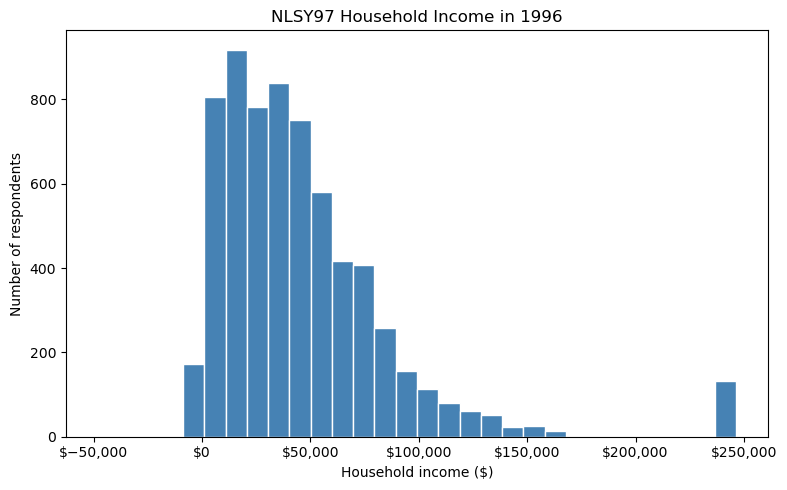

In [14]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

income = nlsy97_clean["R1204500"].drop_nulls().to_list()

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(income, bins=30, color="steelblue", edgecolor="white")

ax.set_title("NLSY97 Household Income in 1996")
ax.set_xlabel("Household income ($)")
ax.set_ylabel("Number of respondents")
ax.xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))

plt.tight_layout()
plt.show()

### Household income distribution

Household income is right-skewed, with most values below
$100,000 and fewer households reporting high incomes. The
median is $37,650, and the middle 50% falls between $18,000
and $61,300.

There are three valid negative income amounts. The separate
bar near $246,000 reflects the dataset’s top-coding: the highest
2% of incomes were replaced with their group average. This
means we cannot see the full spread of the highest incomes.

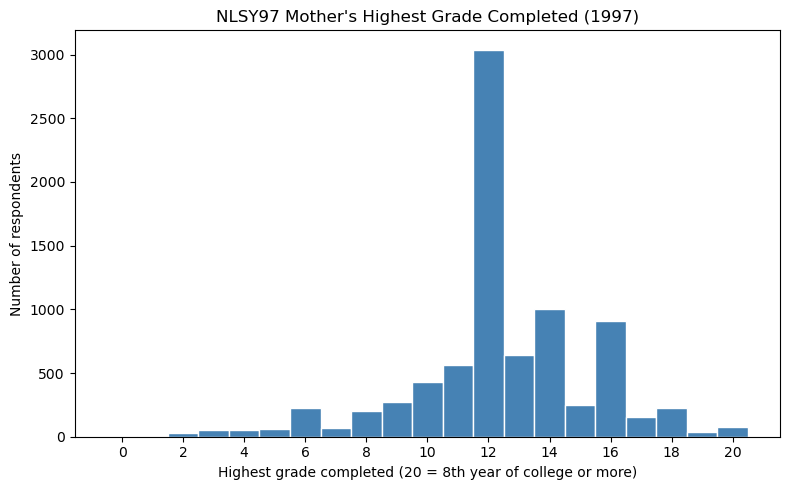

In [15]:
education = nlsy97_clean["R1302500"].drop_nulls().to_list()

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(
    education,
    bins=[x - 0.5 for x in range(22)],
    color="steelblue",
    edgecolor="white"
)

ax.set_title("NLSY97 Mother's Highest Grade Completed (1997)")
ax.set_xlabel("Highest grade completed (20 = 8th year of college or more)")
ax.set_ylabel("Number of respondents")
ax.set_xticks(range(0, 21, 2))

plt.tight_layout()
plt.show()

### Mother’s education distribution

The most common education level is 12th grade, which is also
the median. The middle 50% falls between grades 12 and 14.
There are smaller peaks at 14 and 16, representing two and
four years of college.

The distribution has one large peak with values spread on
both sides, rather than a smooth bell shape. The recorded
levels range from 1 to 20, where 20 includes eight years of
college or more.

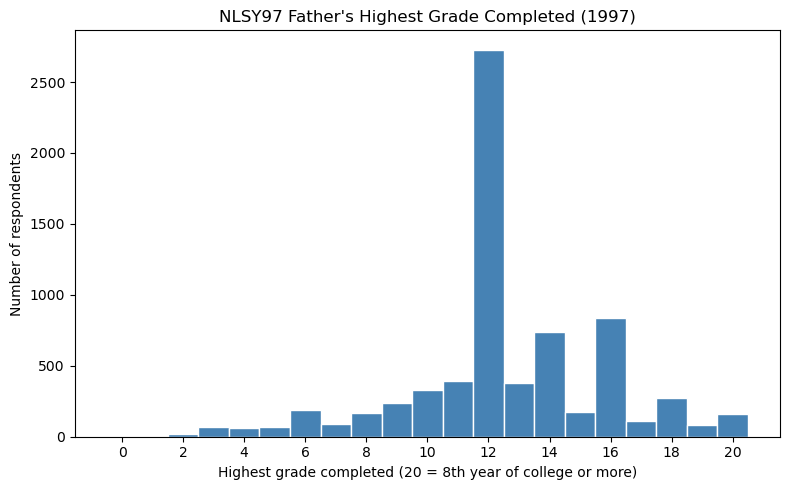

In [16]:
education = nlsy97_clean["R1302400"].drop_nulls().to_list()

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(
    education,
    bins=[x - 0.5 for x in range(22)],
    color="steelblue",
    edgecolor="white"
)

ax.set_title("NLSY97 Father's Highest Grade Completed (1997)")
ax.set_xlabel("Highest grade completed (20 = 8th year of college or more)")
ax.set_ylabel("Number of respondents")
ax.set_xticks(range(0, 21, 2))

plt.tight_layout()
plt.show()

### Father’s education distribution

The most common education level is 12th grade, which is also
the median. The middle 50% falls between grades 12 and 14.
There are also concentrations at college education levels.
Values range from 1 to 20, with 20 representing eight years
of college or more.

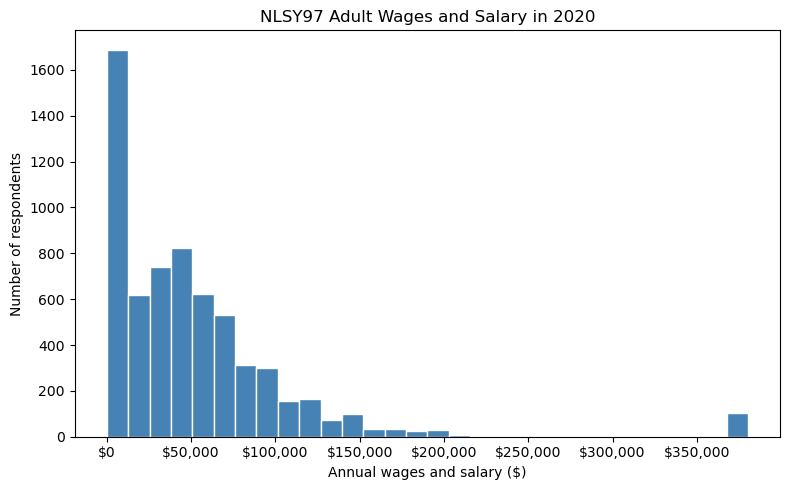

In [17]:
wages = nlsy97_clean["U5753500"].drop_nulls().to_list()

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(wages, bins=30, color="steelblue", edgecolor="white")

ax.set_title("NLSY97 Adult Wages and Salary in 2020")
ax.set_xlabel("Annual wages and salary ($)")
ax.set_ylabel("Number of respondents")
ax.xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))

plt.tight_layout()
plt.show()

### Adult wages distribution

Adult wages in 2020 are right-skewed. Most values are below
$100,000, with a median of $40,000. The middle 50% falls
between $10,000 and $70,000.

The large bar near zero includes respondents with no wage
income and those with small amounts. These are annual wages,
so they do not necessarily represent a full-time salary.
The separate bar near $380,000 reflects the adjustment made
to the highest incomes for privacy.

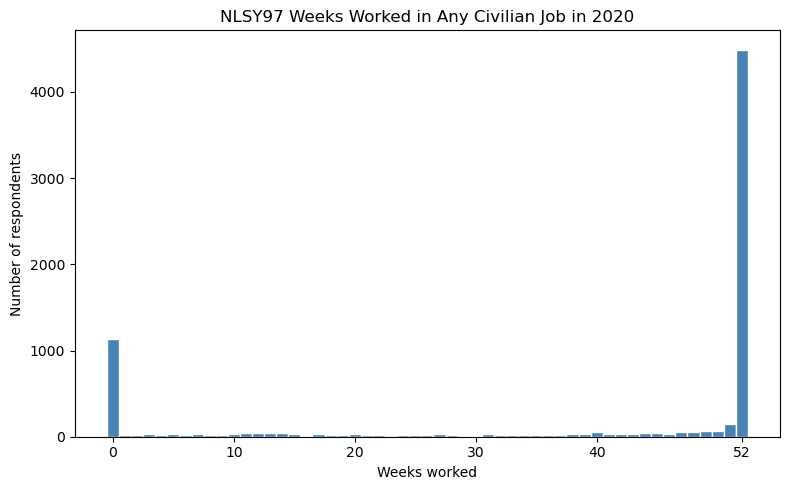

In [18]:
weeks = nlsy97_clean["Z9061911"].drop_nulls().to_list()

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(
    weeks,
    bins=[x - 0.5 for x in range(54)],
    color="steelblue",
    edgecolor="white"
)

ax.set_title("NLSY97 Weeks Worked in Any Civilian Job in 2020")
ax.set_xlabel("Weeks worked")
ax.set_ylabel("Number of respondents")
ax.set_xticks([0, 10, 20, 30, 40, 52])

plt.tight_layout()
plt.show()

### Weeks worked distribution

Most respondents with available data worked 52 weeks in 2020.
There is also a large group who worked 0 weeks, with fewer
respondents spread between these two extremes.

The median is 52 weeks, and the middle 50% falls between
27 and 52 weeks. The distribution is concentrated at the
upper end with a tail toward fewer weeks. Working 52 weeks
does not necessarily mean working full-time hours.

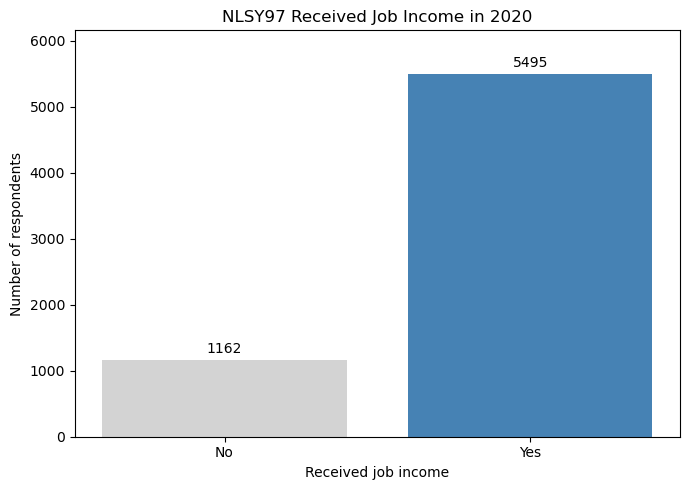

In [19]:
counts = (
    nlsy97_clean
    .filter(pl.col("U5753300").is_not_null())
    .group_by("U5753300")
    .len()
    .sort("U5753300")
)

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(
    ["No", "Yes"],
    counts["len"].to_list(),
    color=["lightgray", "steelblue"]
)

ax.bar_label(bars, padding=3)
ax.set_title("NLSY97 Received Job Income in 2020")
ax.set_xlabel("Received job income")
ax.set_ylabel("Number of respondents")
ax.margins(y=0.12)

plt.tight_layout()
plt.show()

### Job-income receipt

Among the 6,657 respondents with valid answers, 5,495 (82.5%)
received job income in 2020 and 1,162 (17.5%) did not.
We excluded 2,327 missing responses.

This shows that most respondents with available answers received
job income at some point during the year. It does not tell us
whether they worked full-time or were employed the entire year.

Mother, Below 12: median wages = $27,300
Mother, 12: median wages = $40,000
Mother, 13–15: median wages = $45,000
Mother, 16–20: median wages = $60,000
Father, Below 12: median wages = $32,000
Father, 12: median wages = $40,000
Father, 13–15: median wages = $50,000
Father, 16–20: median wages = $60,000


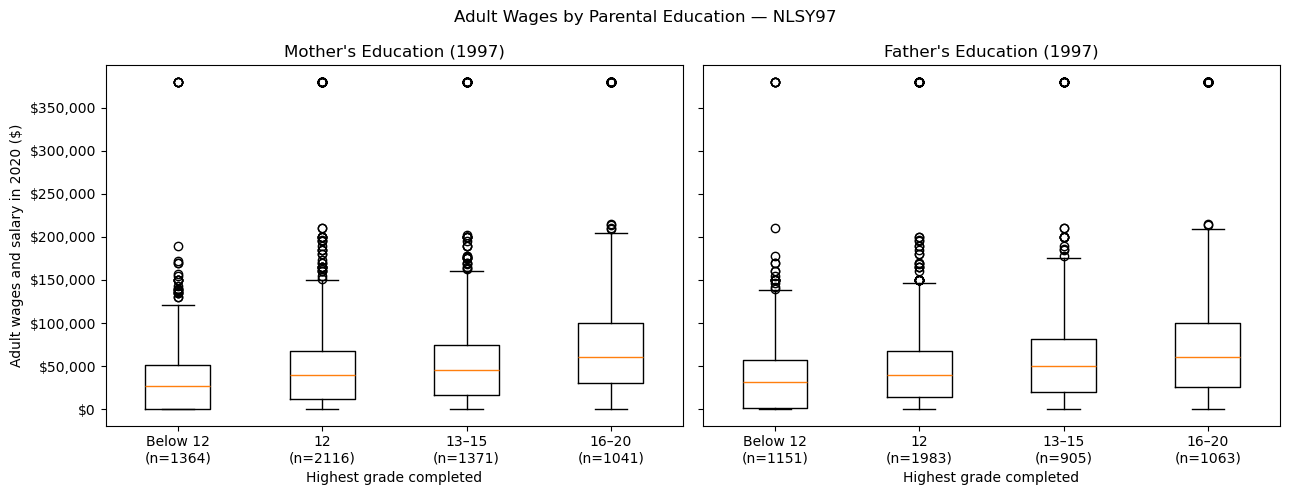

In [20]:
education_groups = [
    ("Below 12", 0, 11),
    ("12", 12, 12),
    ("13–15", 13, 15),
    ("16–20", 16, 20),
]

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

for ax, column, parent in [
    (axes[0], "R1302500", "Mother"),
    (axes[1], "R1302400", "Father"),
]:
    data = nlsy97_clean.select(column, "U5753500").drop_nulls()
    values = []
    labels = []

    for label, low, high in education_groups:
        group = data.filter(
            pl.col(column).is_between(low, high)
        )["U5753500"]

        values.append(group.to_list())
        labels.append(f"{label}\n(n={len(group)})")
        print(f"{parent}, {label}: median wages = ${group.median():,.0f}")

    ax.boxplot(values)
    ax.set_xticks([1, 2, 3, 4])
    ax.set_xticklabels(labels)
    ax.set_title(f"{parent}'s Education (1997)")
    ax.set_xlabel("Highest grade completed")
    ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))

axes[0].set_ylabel("Adult wages and salary in 2020 ($)")
fig.suptitle("Adult Wages by Parental Education — NLSY97")
plt.tight_layout()
plt.show()

### Parental education and adult wages

Median adult wages increase across the parental education groups.
For mother’s education, the medians are $27,300, $40,000,
$45,000, and $60,000. For father’s education, they are $32,000,
$40,000, $50,000, and $60,000.

### So what?

This pattern suggests that higher parental education is associated
with higher adult wages in our sample. It relates directly to our
question about family background and adult earnings. We expected
a positive relationship because parental education may be linked
to educational opportunities and family resources.

However, the boxes overlap, and wages vary within every group.
This does not prove that parental education causes higher wages.
The results are unweighted and only include respondents with
the required information available.

### What next?

We could check whether this pattern remains when comparing people
with similar household incomes or weeks worked. We could also
download respondents’ own education to explore how it relates
to both parental education and wages.

## Part 2: PSID analysis

In [21]:
import polars as pl
from pathlib import Path
import matplotlib.pyplot as plt

psid_J = pl.read_csv("data/raw/psid/J365605.csv")
psid_M = pl.read_csv("data/raw/psid/M365605.csv")

for name, df in [
    ("PSID", psid_J),
    ("PSID linkage", psid_M),
]:
    print(f"\n--- {name} ---")

    print("Shape:", df.shape)

    print("\nColumn names and data types:")
    df.glimpse()

    print("\nMissing values:")
    display(df.null_count())

    print("\nSummary statistics:")
    display(df.describe())
# ER12079 = TOTAL FAMILY INCOME   
# ER12222 = COMPLETED ED-HD
# ER12223 = COMPLETED ED-WF
# TA210679 = E2A AMT OF WAGES/SALARY
# TA210220 = D1 EMPLOYMENT STATUS 1ST MENTION
# TA210225 = D9A TOTAL WEEKS WORKED LAST YEAR
# TA210678 = E1 WHETHER WAGES/SALARY
psid_J[[
    "ER12079",
    "ER12222",
    "ER12223",
    "TA210679",
    "TA210220",
    "TA210225",
    "TA210678"
]].head()


--- PSID ---
Shape: (2362, 25)

Column names and data types:
Rows: 2362
Columns: 25
$ TAS      <i64> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1
$ TAS21    <i64> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1
$ ER30000  <i64> 2, 2, 2, 2, 2, 2, 2, 2, 2, 2
$ ER30001  <i64> 4, 4, 5, 7, 7, 7, 7, 7, 7, 7
$ ER30002  <i64> 42, 44, 33, 46, 47, 48, 49, 50, 51, 52
$ ER32000  <i64> 1, 2, 1, 2, 2, 2, 2, 1, 2, 2
$ ER32006  <i64> 2, 2, 2, 2, 2, 2, 2, 2, 2, 2
$ ER10001  <i64> 7, null, 7, 7, 7, 7, 7, 7, 7, 7
$ ER12079  <f64> 7512.0, null, 46473.03, 14000.0, 14000.0, 14000.0, 58200.0, 11400.0, 14000.0, 11400.0
$ ER12222  <i64> 12, null, 10, 11, 11, 11, 12, 10, 11, 10
$ ER12223  <i64> 0, null, 12, 0, 0, 0, 12, 11, 0, 11
$ ER33401  <i64> 4246, 0, 3633, 5107, 5107, 5107, 1910, 1111, 5107, 1111
$ ER33402  <i64> 3, 0, 5, 2, 4, 5, 0, 0, 0, 0
$ ER33403  <i64> 30, 0, 30, 30, 30, 30, 0, 0, 0, 0
$ ER34901  <i64> 7535, 3753, 4065, 6614, 4476, 4239, 6528, 4020, 6582, 4020
$ ER34902  <i64> 1, 2, 1, 2, 2, 1, 2, 2, 2, 3
$ ER34903  <i64> 10, 30, 10,

TAS,TAS21,ER30000,ER30001,ER30002,ER32000,ER32006,ER10001,ER12079,ER12222,ER12223,ER33401,ER33402,ER33403,ER34901,ER34902,ER34903,TA210001,TA210002,TA210003,TA210004,TA210220,TA210225,TA210678,TA210679
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,206,206,206,206,0,0,0,0,0,0,0,0,0,0,0,0,0,0



Summary statistics:


statistic,TAS,TAS21,ER30000,ER30001,ER30002,ER32000,ER32006,ER10001,ER12079,ER12222,ER12223,ER33401,ER33402,ER33403,ER34901,ER34902,ER34903,TA210001,TA210002,TA210003,TA210004,TA210220,TA210225,TA210678,TA210679
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",2362.0,2362.0,2362.0,2362.0,2362.0,2362.0,2362.0,2156.0,2156.0,2156.0,2156.0,2362.0,2362.0,2362.0,2362.0,2362.0,2362.0,2362.0,2362.0,2362.0,2362.0,2362.0,2362.0,2362.0,2362.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,206.0,206.0,206.0,206.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",1.0,1.0,2.0,3439.245131,50.563082,1.528789,2.005927,7.0,39188.625867,16.408163,11.196197,3657.917866,1.511008,11.631668,5063.024132,6.223539,24.207875,1.0,1183.27011,5063.024132,6.223539,4.753175,30.798476,2.324301,527758.147756
"""std""",0.0,0.0,0.0,2121.752279,48.114227,0.499276,0.44708,0.0,34668.273046,18.640609,18.432192,2769.325304,4.105152,17.45807,2502.924305,13.534588,11.550103,0.0,683.70514,2502.924305,13.534588,13.646488,22.478943,1.998049,2.2016e6
"""min""",1.0,1.0,2.0,4.0,1.0,1.0,1.0,7.0,-64500.0,0.0,0.0,0.0,0.0,0.0,19.0,1.0,10.0,1.0,1.0,19.0,1.0,1.0,0.0,1.0,0.0
"""25%""",1.0,1.0,2.0,1583.0,33.0,1.0,2.0,7.0,16212.0,11.0,0.0,1421.0,0.0,0.0,3044.0,1.0,10.0,1.0,591.0,3044.0,1.0,1.0,0.0,1.0,0.0
"""50%""",1.0,1.0,2.0,3111.0,37.0,2.0,2.0,7.0,29600.0,12.0,11.0,3515.0,0.0,0.0,5302.0,2.0,30.0,1.0,1183.0,5302.0,2.0,1.0,40.0,1.0,9953.0
"""75%""",1.0,1.0,2.0,5573.0,45.0,2.0,2.0,7.0,53500.0,15.0,14.0,5195.0,3.0,30.0,7328.0,3.0,30.0,1.0,1776.0,7328.0,3.0,6.0,52.0,5.0,30000.0
"""max""",1.0,1.0,2.0,6867.0,251.0,2.0,4.0,7.0,386250.0,99.0,99.0,10442.0,74.0,97.0,9243.0,52.0,98.0,1.0,2367.0,9243.0,52.0,99.0,52.0,9.0,9.999999e6



--- PSID linkage ---
Shape: (21511, 116)

Column names and data types:
Rows: 21511
Columns: 116
$ CDSCUMREL  <i64> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1
$ CDSCUMID68 <i64> 4, 4, 4, 4, 4, 4, 4, 4, 4, 4
$ CDSCUMPN   <i64> 3, 5, 7, 31, 36, 37, 38, 39, 41, 42
$ CDSTYPE97  <i64> 3, 2, 2, 2, 2, 1, 1, 1, 1, 1
$ CRFID97    <i64> 3854, 3853, 5491, 4246, 5490, 4773, 5491, 3854, 4246, 4246
$ CRSN97     <i64> 1, 2, 1, 1, 2, 3, 2, 4, 2, 3
$ CDS_HID97  <i64> 922, 0, 0, 1022, 0, 0, 0, 922, 1022, 1022
$ CDS_SN97   <i64> 0, 0, 0, 1, 0, 0, 0, 0, 0, 0
$ ID68PCG97  <i64> 0, 0, 0, 0, 0, 4, 4, 4, 4, 4
$ PNPCG97    <i64> 0, 0, 0, 0, 0, 179, 7, 173, 31, 31
$ CRPCGFID97 <i64> 0, 0, 0, 0, 0, 4773, 5491, 3854, 4246, 4246
$ CRPCGSN97  <i64> 0, 0, 0, 0, 0, 1, 1, 2, 1, 1
$ ID68OCG97  <i64> 0, 0, 0, 0, 0, 0, 0, 4, 0, 0
$ PNOCG97    <i64> 0, 0, 0, 0, 0, 0, 0, 3, 0, 0
$ CROCGFID97 <i64> 0, 0, 0, 0, 0, 0, 0, 3854, 0, 0
$ CROCGSN97  <i64> 0, 0, 0, 0, 0, 0, 0, 1, 0, 0
$ DEMOG_97   <i64> 0, 0, 0, 0, 0, 1, 1, 1, 1, 1
$ PCGHH_97   

CDSCUMREL,CDSCUMID68,CDSCUMPN,CDSTYPE97,CRFID97,CRSN97,CDS_HID97,CDS_SN97,ID68PCG97,PNPCG97,CRPCGFID97,CRPCGSN97,ID68OCG97,PNOCG97,CROCGFID97,CROCGSN97,DEMOG_97,PCGHH_97,PCGCH_97,CHILD_97,CDSTYPE02,CRFID02,CRSN02,CDS_HID02,CDS_SN02,ID68PCG02,PNPCG02,CRPCGFID02,CRPCGSN02,ID68OCG02,PNOCG02,CROCGFID02,CROCGSN02,DEMOG_02,PCGHH_02,PCGCH_02,CHILD_02,…,PCGHHNO19,DEMOG_19,PCGHH_19,PCGCH_19,CHILD_19,PCGHH_20,PCGCH_20,CDSTYPE21,CRFID21,CRSN21,CDS_HID21,CDS_SN21,ID68PCG21,PNPCG21,CRPCGFID21,CRPCGSN21,CDSPCGSN21,PCGHHNO21,DEMOG_21,PCGHH_21,PCGCH_21,CHILD_21,CDSTYPE24,CRFID24,CRSN24,CDS_HID24,CDS_SN24,ID68PCG24,PNPCG24,CRPCGFID24,CRPCGSN24,CDSPCGSN24,PCGHHNO24,DEMOG_24,PCGHH_24,PCGCH_24,CHILD_24
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,…,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0



Summary statistics:


statistic,CDSCUMREL,CDSCUMID68,CDSCUMPN,CDSTYPE97,CRFID97,CRSN97,CDS_HID97,CDS_SN97,ID68PCG97,PNPCG97,CRPCGFID97,CRPCGSN97,ID68OCG97,PNOCG97,CROCGFID97,CROCGSN97,DEMOG_97,PCGHH_97,PCGCH_97,CHILD_97,CDSTYPE02,CRFID02,CRSN02,CDS_HID02,CDS_SN02,ID68PCG02,PNPCG02,CRPCGFID02,CRPCGSN02,ID68OCG02,PNOCG02,CROCGFID02,CROCGSN02,DEMOG_02,PCGHH_02,PCGCH_02,…,PCGHHNO19,DEMOG_19,PCGHH_19,PCGCH_19,CHILD_19,PCGHH_20,PCGCH_20,CDSTYPE21,CRFID21,CRSN21,CDS_HID21,CDS_SN21,ID68PCG21,PNPCG21,CRPCGFID21,CRPCGSN21,CDSPCGSN21,PCGHHNO21,DEMOG_21,PCGHH_21,PCGCH_21,CHILD_21,CDSTYPE24,CRFID24,CRSN24,CDS_HID24,CDS_SN24,ID68PCG24,PNPCG24,CRPCGFID24,CRPCGSN24,CDSPCGSN24,PCGHHNO24,DEMOG_24,PCGHH_24,PCGCH_24,CHILD_24
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,…,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0,21511.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",1.0,3303.368277,67.548185,0.711775,3586.183859,1.439264,168.983869,0.072475,550.785087,11.684115,633.452931,0.291014,335.324811,10.047464,453.410627,0.142625,0.165636,0.071405,0.165636,0.103342,0.576821,3623.256613,1.908698,283.478825,0.093812,445.915392,9.593836,518.068244,0.226256,253.10139,8.393148,326.438706,0.119799,0.13514,0.093348,0.13514,…,0.342662,0.215192,0.121612,0.214541,0.07359,0.0536,0.092836,0.471666,3572.823765,3.32588,8070.126075,0.536098,418.845474,9.227697,518.749152,0.188415,0.186788,0.197852,0.120404,0.073265,0.120404,0.034819,0.715866,3506.509832,3.407791,12360.45135,0.83111,660.098647,14.876435,877.95328,0.304914,0.284506,0.301334,0.190228,0.106969,0.189252,0.054298
"""std""",0.0,2131.413257,72.820843,1.085105,2726.576401,4.232418,376.528991,0.26337,1525.000989,41.730246,1787.347339,0.695681,1162.572794,39.942417,1572.065236,1.142974,0.371762,0.257507,0.371762,0.304413,1.009826,2239.140349,6.576421,542.316199,0.293165,1387.598519,40.423918,1504.44782,0.766324,1013.163469,36.887113,1202.714335,1.144759,0.341881,0.290926,0.341881,…,0.477345,0.410965,0.326845,0.410513,0.261109,0.225233,0.29021,1.039358,3079.326771,10.138955,16260.720989,1.229608,1334.132406,36.559674,1607.094565,0.534072,0.52997,0.398856,0.32544,0.260577,0.32544,0.183326,1.164391,3094.782839,10.284757,18892.452468,1.515876,1635.743304,45.246628,2101.819335,1.213228,0.635346,0.462079,0.39249,0.30908,0.391718,0.22661
"""min""",1.0,4.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""25%""",1.0,1475.0,31.0,0.0,1426.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1767.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""50%""",1.0,2782.0,38.0,0.0,3368.0,0.0,0.0,0

ER12079,ER12222,ER12223,TA210679,TA210220,TA210225,TA210678
f64,i64,i64,i64,i64,i64,i64
7512.0,12,0,27000,1,25,1
null,null,null,0,6,0,5
46473.03,10,12,0,1,0,5
14000.0,11,0,700,1,11,1
14000.0,11,0,20000,1,52,1


Check employment codes, wage-receipt codes, ambiguous zeros, and valid ranges

In [22]:
psid_J["TA210220"].value_counts(sort=True)

TA210220,count
i64,u32
1,1290
7,433
3,324
6,172
2,77
99,47
5,19


In [23]:
psid_J["TA210678"].value_counts(sort=True)

TA210678,count
i64,u32
1,1613
5,716
9,33


In [24]:
psid_J["TA210679"].value_counts(sort=True)

TA210679,count
i64,u32
0,614
9999999,121
20000,59
30000,53
10000,45
…,…
11744,1
6240,1
19076,1


Value/Range: 
	
For the employment codes (TA210220), I found the values in that columns are all integers and each int is associated with a level of employment. 1 had the highest number of rows. 1 = Working now, including Military, 2 = Only temporarily laid off, sick or maternity leave, 3 = Looking for work, unemployed, 4 = Retired, 5 = Disabled, permanently or temporarily, 6 = Keeping house, 7 = Student, 8 = Other, 99 = NA; refused. 

For the wage_reciept codes (TA210678), the question they're asking is "Did you earn wages or salaries in 2020 from working on any jobs?". 1 = Yes, 5 = No, 9 = DK; NA; refused.

For the wother wage_reciept codes (TA210679), the question they're asking is "How much did you earn altogether from wages or salaries in 2020, that is, before anything was deducted for taxes or other things?". 9,999,996 = actual ammount, 9,999,997 = $9,999,997 or more, 9,999,999 = 	DK; NA; refused, 0 = did not earn wages or salaries in 2020.

Review the linkage file and check unique person keys.

In [25]:
print(psid_M["CDSCUMID68"].shape)
print(psid_M["CDSCUMPN"].shape)
print(psid_J["ER30001"].shape)
print(psid_J["ER30002"].shape)
duplicates = psid_M.filter(psid_M.is_duplicated())
print(duplicates)
psid_M.select(
    pl.col("CDSCUMID68").is_null().sum(),
    pl.col("CDSCUMPN").is_null().sum()
)
psid_J.select(
    pl.col("ER30001").is_null().sum(),
    pl.col("ER30002").is_null().sum()
)



(21511,)
(21511,)
(2362,)
(2362,)
shape: (0, 116)
┌───────────┬────────────┬──────────┬───────────┬───┬──────────┬──────────┬──────────┬──────────┐
│ CDSCUMREL ┆ CDSCUMID68 ┆ CDSCUMPN ┆ CDSTYPE97 ┆ … ┆ DEMOG_24 ┆ PCGHH_24 ┆ PCGCH_24 ┆ CHILD_24 │
│ ---       ┆ ---        ┆ ---      ┆ ---       ┆   ┆ ---      ┆ ---      ┆ ---      ┆ ---      │
│ i64       ┆ i64        ┆ i64      ┆ i64       ┆   ┆ i64      ┆ i64      ┆ i64      ┆ i64      │
╞═══════════╪════════════╪══════════╪═══════════╪═══╪══════════╪══════════╪══════════╪══════════╡
└───────────┴────────────┴──────────┴───────────┴───┴──────────┴──────────┴──────────┴──────────┘


ER30001,ER30002
u32,u32
0,0


In [26]:


M_ids = psid_M.select(
    pl.col("CDSCUMID68").alias("ID68"),
    pl.col("CDSCUMPN").alias("PN68")
).unique()

J_ids = psid_J.select(
    pl.col("ER30001").alias("ID68"),
    pl.col("ER30002").alias("PN68")
).unique()

# IDs in both files
matching_ids = M_ids.join(
    J_ids,
    on=["ID68", "PN68"],
    how="inner"
)

print("Unique IDs in M:", M_ids.shape[0])
print("Unique IDs in J:", J_ids.shape[0])
print("IDs found in both:", matching_ids.shape[0])


Unique IDs in M: 21511
Unique IDs in J: 2362
IDs found in both: 2097


Linkage Findings:
CDSCUMID68 and CDSCUMPN are person indentifiers. I found that there was a link between columns in psid_J and psid_M, however, only 2097 of the id's seem to match.

Check whether respondents belonged to the recorded 1997 household before using its income and education as background.

In [27]:
# ER30001	1968 interview number
# ER30002	Person number assigned in 1968
# ER33401	1997 interview number
# ER33402	1997 person sequence number
# ER33403	Relationship to household head in 1997
# CRFID97	1997 family identifier in the linkage file (exact definition needs verification)
# CRSN97	1997 sequence/person identifier in the linkage file (exact definition needs verification)
# CDS_HID97	1997 household identifier associated with CDS linkage
# CDS_SN97	1997 sequence number associated with CDS linkage



linked = psid_J.join(
    psid_M,
    left_on=["ER30001", "ER30002"],
    right_on=["CDSCUMID68", "CDSCUMPN"],
    how="left"
)
linked.select([
    "ER30001",
    "ER30002",
    "ER33401",
    "ER33402",
    "ER33403",
    "CRFID97",
    "CRSN97",
    "CDS_HID97",
    "CDS_SN97"
]).head(20)


linked = linked.with_columns(
    pl.when(
        pl.col("ER33401").is_null()
        | pl.col("ER33402").is_null()
        | pl.col("CRFID97").is_null()
        | pl.col("CRSN97").is_null()
    )
    .then(pl.lit("Unconfirmed"))
    .when(
        (pl.col("ER33401") == pl.col("CRFID97"))
        & (pl.col("ER33402") == pl.col("CRSN97"))
    )
    .then(pl.lit("Match"))
    .otherwise(pl.lit("Mismatch"))
    .alias("household_status")
)

print(linked["household_status"].value_counts())


shape: (2, 2)
┌──────────────────┬───────┐
│ household_status ┆ count │
│ ---              ┆ ---   │
│ str              ┆ u32   │
╞══════════════════╪═══════╡
│ Unconfirmed      ┆ 265   │
│ Match            ┆ 2097  │
└──────────────────┴───────┘


There are 2,097 matches for household identifiers and 265 unconfirmed. The way we can link these two datasets together that makes the most sense for the answer we are trying to answer is household income.

Explain the limits of using household-head/spouse education as a measure of parental education.

Some of the limits of using household-head/spouse education could be that some parents may not have pursued further education, but still managed to make as much money as those that did. The household head may not be the child's parent instead it could the child'd grandparents, aunt, uncle, sibling, etc. Income can also come from multiple family members which could skew results for children that are only provided by parents.

Plot family income, both education measures, adult wages, employment status, and weeks worked.

(2362,)
(2362,)


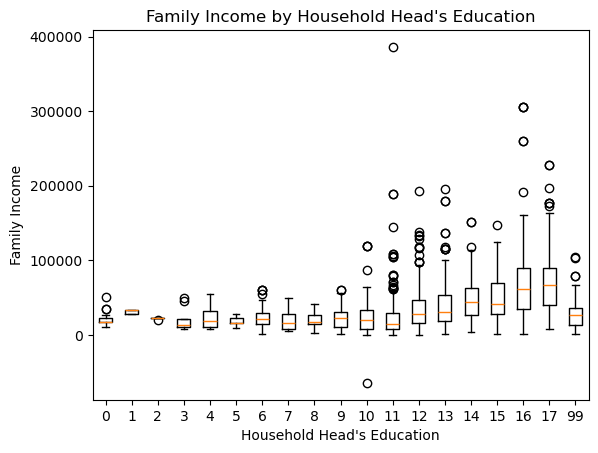

In [28]:
# Measure	Column name	Description
# Family income	ER12079	Total family income for 1996
# Head's education	ER12222	Completed education of household head
# Spouse's education	ER12223	Completed education of spouse
# Adult wages/salary	TA210679	Amount of wages/salary reported in the 2021 Transition into Adulthood Supplement
# Employment status	TA210220	Employment status, first mention, in the 2021 Transition into Adulthood Supplement
# Weeks worked	TA210225	Total weeks worked last year, in the 2021 Transition into Adulthood Supplement

# 0	Completed no grades of school
# 1–8	Completed grades 1–8
# 9–11	Completed grades 9–11
# 12	Completed 12th grade
# 13–16	Completed 13–16 grades/years of education
# 17	Completed at least some postgraduate work
# 99	Not available / don't know

# Plot 1: relation between Family income and Head's education (Box Plot)
print(psid_J["ER12079"].shape)
print(psid_J["ER12222"].shape)


plot_df = psid_J.select([
    "ER12222",
    "ER12079"
]).drop_nulls()

education_levels = plot_df["ER12222"].unique().sort().to_list()

income_by_education = [
    plot_df.filter(
        pl.col("ER12222") == level
    )["ER12079"].to_list()
    for level in education_levels
]

plt.boxplot(income_by_education, tick_labels=education_levels)

plt.xlabel("Household Head's Education")
plt.ylabel("Family Income")
plt.title("Family Income by Household Head's Education")
plt.show()

(2362,)
(2362,)
shape: (10, 2)
┌──────────┬──────────┐
│ TA210220 ┆ TA210679 │
│ ---      ┆ ---      │
│ i64      ┆ i64      │
╞══════════╪══════════╡
│ 1        ┆ 9999999  │
│ 3        ┆ 9999999  │
│ 1        ┆ 9999999  │
│ 1        ┆ 9999999  │
│ 6        ┆ 9999999  │
│ 1        ┆ 9999999  │
│ 2        ┆ 9999999  │
│ 1        ┆ 9999999  │
│ 1        ┆ 9999999  │
│ 1        ┆ 9999999  │
└──────────┴──────────┘


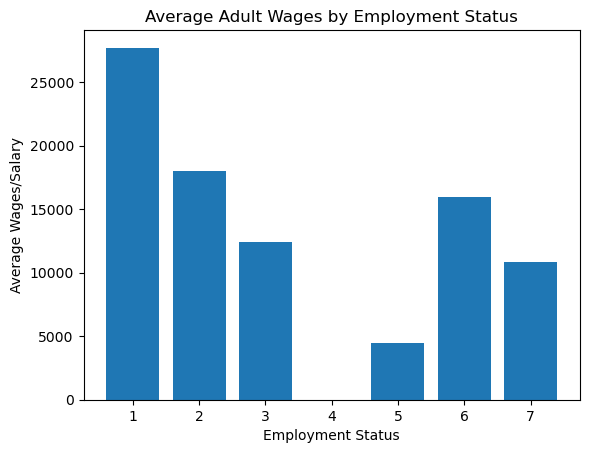

In [29]:
# Plot 2: relation between Adult wages/salary and Employment status (Bar Graph)

print(psid_J["TA210220"].shape)
print(psid_J["TA210679"].shape)
print(
    psid_J.select(["TA210220", "TA210679"])
    .filter(pl.col("TA210679").is_not_null())
    .sort("TA210679", descending=True)
    .head(10)
)
plot_df = psid_J.select([
    "TA210220",
    "TA210679"
]).drop_nulls()

# Keep valid employment categories and positive wages
plot_df = plot_df.filter(
    pl.col("TA210220").is_in([1, 2, 3, 5, 6, 7]) &
    (pl.col("TA210679") > 0)&
    (pl.col("TA210679") != 9999999)
)

# Calculate average wages for each employment status
summary = (
    plot_df.group_by("TA210220")
    .agg(pl.col("TA210679").mean().alias("Average Wages"))
    .sort("TA210220")
)

# Create the bar chart
plt.bar(
    summary["TA210220"].to_list(),
    summary["Average Wages"].to_list()
)

plt.xlabel("Employment Status")
plt.ylabel("Average Wages/Salary")
plt.title("Average Adult Wages by Employment Status")
plt.show()

Add distribution notes beside each plot.

-Plot 1-

Shape: Is the distribution skewed left, skewed right, or roughly symmetric?
The distrubtion is left skewed.


Most common values: Where do most observations fall?
The higher the income the more likley is that the parent recieved higher education.


Spread: Are the values close together or spread out?

The values seem to be generally close together which you can see on the left side of the plot where the boxes are smaller indicating more clustered values.a

Unusual observations: Are there outliers, extreme values, or unexpected codes?

There seems to be one instance of an outlier being lower than the IQR range. Also the farther down the plot you go, the more outliers there are and those tend to be higher than the average.

Main takeaway: What does the distribution tell you about the data?
There seems to be a trend of higher education producing high family incomes.

-Plot 2-

The average reported wages and salary vary across employment status categories. Category 1 (employed) has the highest reported wage and category 5 (disables) had the lowest. This distribution shows a trend of people that are employed or only taking temporary leave having higher wages and those that are unemployed or  retired having lower wages. Categories 4 has no visible bars which could be due to the fact that 4 represents retired. Overall, the chart suggests differences in reported wages across employment categories, although the number of observations in each category and the meaning of the wage units should be verified before drawing conclusions.

Add "so what?", expected/unexpected, and "what next?" notes.

This EDA finding showed that houshold income could be a good predictor for a child's future earnings. The higher education correlating with higher wages was expected and so was the wages and employment status. Some next steps could be further cleaning the columns that are helpful in answering this question and exploring more relations between the child's future income and other data values. 

### PSID distributions

Distribution plots for the PSID research features. Unknown codes (99 for education, 9,999,999 for wages) are excluded. Summary statistics are printed below each plot.

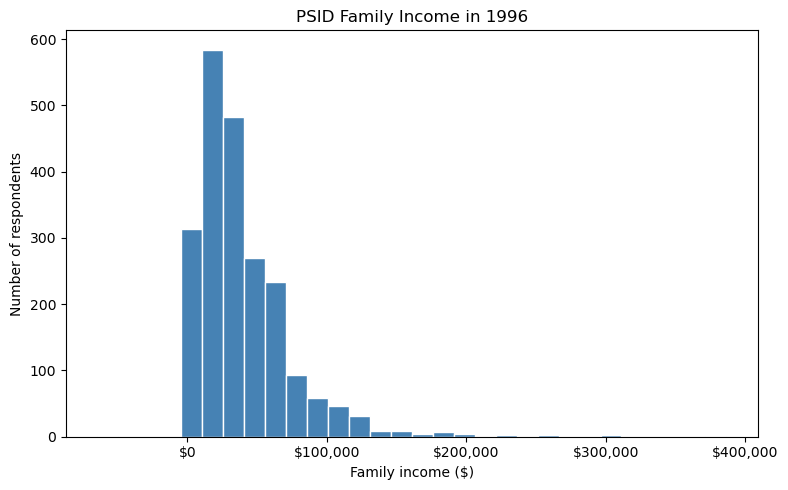

Family Income in 1996 | n = 2156 | min = -64500.0 | 25% = 16196.5 | median = 29539.43 | 75% = 53500.0 | max = 386250.0


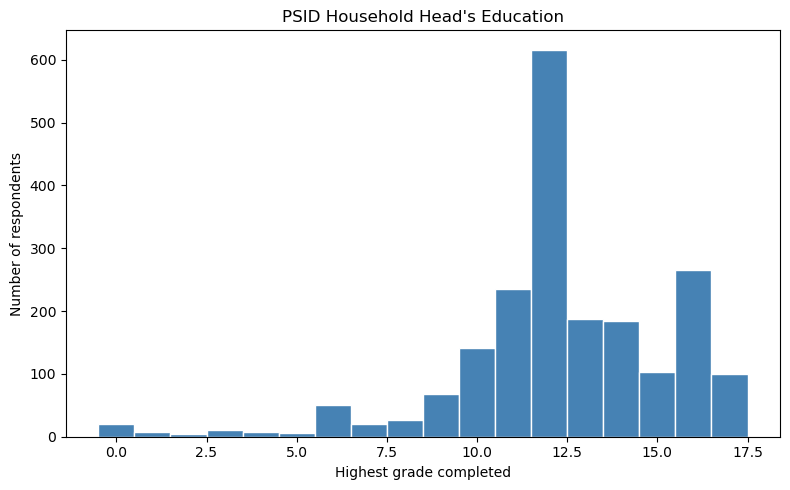

Household Head's Education | n = 2054 | min = 0 | 25% = 11.0 | median = 12.0 | 75% = 14.0 | max = 17


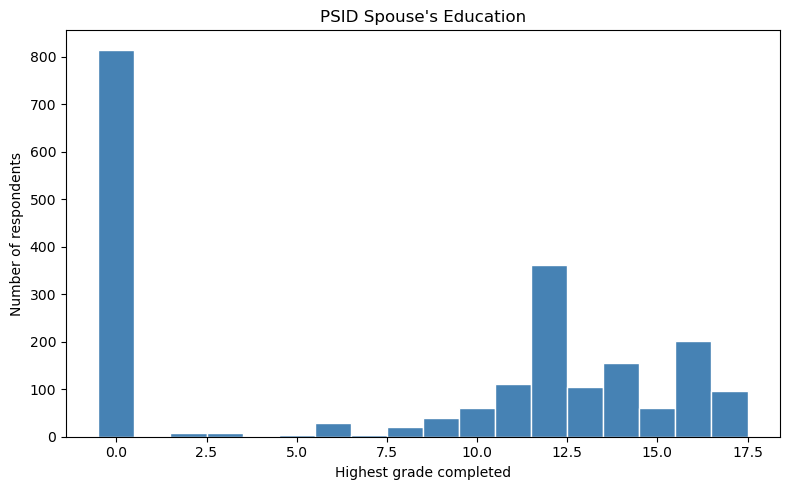

Spouse's Education | n = 2076 | min = 0 | 25% = 0.0 | median = 11.0 | 75% = 13.0 | max = 17


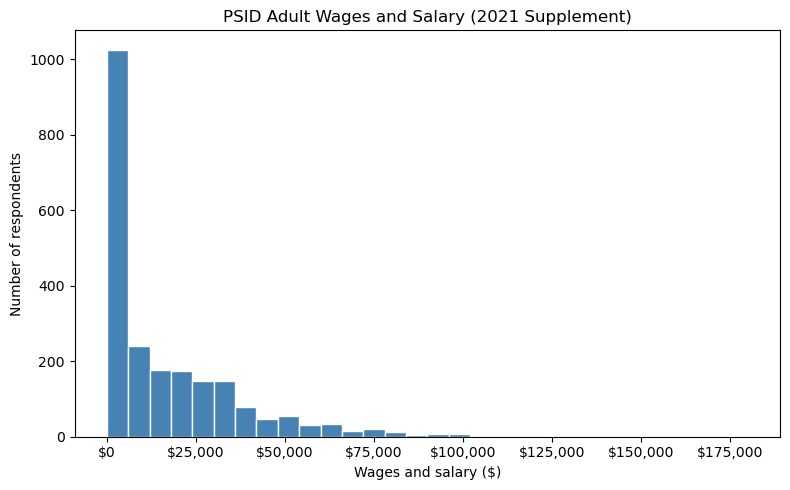

Adult Wages and Salary (2021 Supplement) | n = 2241 | min = 0 | 25% = 0.0 | median = 8000.0 | 75% = 25000.0 | max = 180000


In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

features = [
    ("ER12079", "Family Income in 1996", "Family income ($)", False, None),
    ("ER12222", "Household Head's Education", "Highest grade completed", True, 99),
    ("ER12223", "Spouse's Education", "Highest grade completed", True, 99),
    ("TA210679", "Adult Wages and Salary (2021 Supplement)", "Wages and salary ($)", False, 9999999),
]

for column, title, xlabel, is_education, missing_code in features:
    values = [v for v in psid_clean[column].drop_nulls().to_list() if v != missing_code]
    series = pd.Series(values)
    fig, ax = plt.subplots(figsize=(8, 5))
    if is_education:
        ax.hist(values, bins=np.arange(-0.5, 18.5, 1), color="steelblue", edgecolor="white")
    else:
        ax.hist(values, bins=30, color="steelblue", edgecolor="white")
        ax.xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
    ax.set_title(f"PSID {title}")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Number of respondents")
    plt.tight_layout()
    plt.show()
    print(
        title, "| n =", len(values), "| min =", series.min(),
        "| 25% =", series.quantile(0.25), "| median =", series.median(),
        "| 75% =", series.quantile(0.75), "| max =", series.max(),
    )


### PSID distribution notes

**Family income (1996).** 2,156 respondents have an income value. The median is $29,539, and the middle half falls between $16,197 and $53,500. The distribution is skewed right, with a long tail of higher incomes up to $386,250. One negative value (-$64,500) is kept because the codebook allows business or farm losses.

**Head's education.** 2,054 respondents have a valid value. The median is 12 grades and the middle half is between 11 and 14, so most household heads finished high school and the values are tightly clustered. The maximum is 17 (some postgraduate work).

**Spouse's education.** 2,076 respondents have a valid value. The median is 11, but the 25th percentile is 0, so about a quarter or more of the values are 0. This may reflect having no spouse rather than no schooling. We have not confirmed that in the codebook, so spouse education should be used with care.

**Adult wages (2021 supplement).** 2,241 respondents have a valid value after removing the 9,999,999 code. The median is $8,000, the 25th percentile is $0, and the 75th is $25,000, with a maximum of $180,000. Many values are 0, because the codebook uses 0 for people who reported no wages or did not answer whether they earned wages. The distribution is skewed right.

Each plot shows one variable only and says nothing yet about relationships between them.

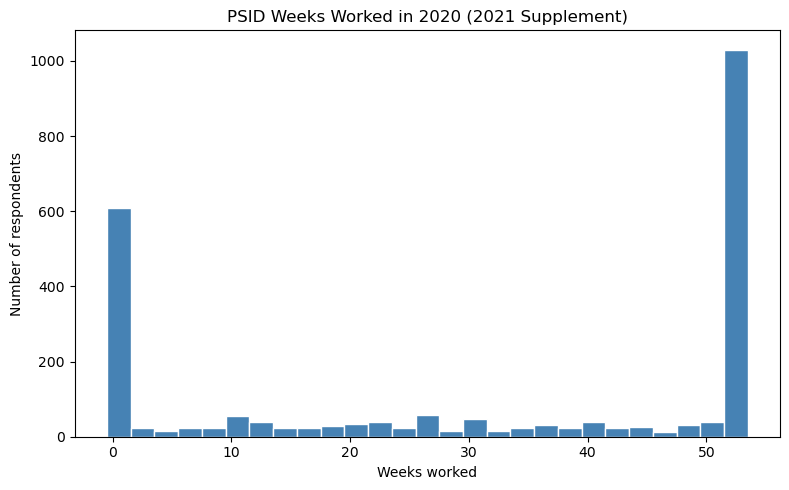

n = 2362 | zero weeks = 596 | 52 weeks = 1030


In [31]:
import numpy as np
import matplotlib.pyplot as plt

weeks = psid_clean["TA210225"].drop_nulls().to_list()

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(weeks, bins=np.arange(-0.5, 54.5, 2), color="steelblue", edgecolor="white")
ax.set_title("PSID Weeks Worked in 2020 (2021 Supplement)")
ax.set_xlabel("Weeks worked")
ax.set_ylabel("Number of respondents")
plt.tight_layout()
plt.show()

print("n =", len(weeks), "| zero weeks =", sum(1 for w in weeks if w == 0), "| 52 weeks =", sum(1 for w in weeks if w == 52))


**Weeks worked (2020).** All 2,362 respondents have a value, from 0 to 52. The distribution has two large clusters: 1,030 respondents (about 44%) worked all 52 weeks and 596 (about 25%) worked 0 weeks, with the rest spread in between. The median is 40 and the mean is 30.8, but neither describes a typical respondent, because most people are at one end or the other. The codebook says time off such as vacation and sick time is not counted.

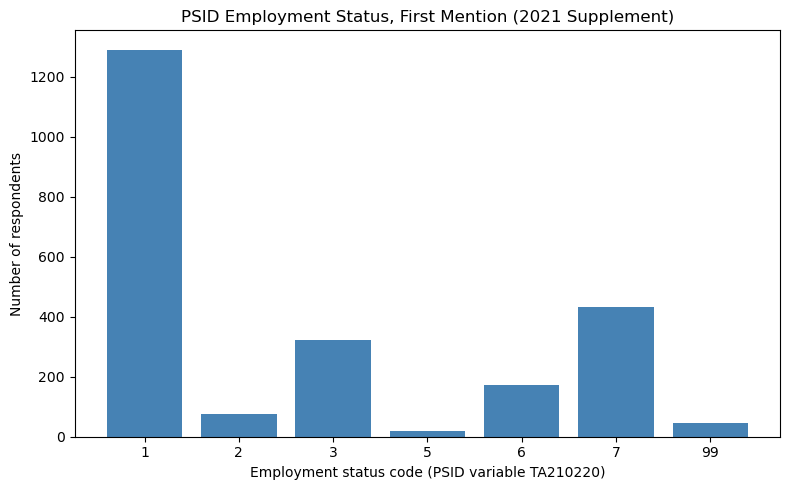

{1: 1290, 2: 77, 3: 324, 5: 19, 6: 172, 7: 433, 99: 47}


In [32]:
import matplotlib.pyplot as plt

values = psid_clean["TA210220"].drop_nulls().to_list()
counts = {}
for value in values:
    counts[value] = counts.get(value, 0) + 1
labels = sorted(counts)

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar([str(label) for label in labels], [counts[label] for label in labels], color="steelblue")
ax.set_title("PSID Employment Status, First Mention (2021 Supplement)")
ax.set_xlabel("Employment status code (PSID variable TA210220)")
ax.set_ylabel("Number of respondents")
plt.tight_layout()
plt.show()

print({label: counts[label] for label in labels})


**Employment status (first mention).** All 2,362 respondents have a value. Code 1 is by far the most common (1,290 respondents, about 55%), followed by codes 7 (433), 3 (324), 6 (172), and 2 (77). Code 5 appears 19 times and code 99 appears 47 times. The codes are shown as they appear in the PSID file. We did not find the meaning of code 99 in the codebook text we checked, so it is left as is.

## Part 3: Secondary datasets

#Opportunity Insights and ELS Exploratory Analysis
This notebook explores the relationship between family
socioeconomic background and later outcomes using
Opportunity Insights and ELS data.

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load ELS datasets
els_a = pd.read_csv("data/raw/els/sophomorefinances2a.csv")
els_b = pd.read_csv("data/raw/els/sophomorefinances2b.csv")

# Load Opportunity Insights dataset
oi = pd.read_excel("data/raw/opportunity_insights/gender_nat.xls")

# Preview datasets
display(els_a.head())
display(els_b.head())
display(oi.head())

,"2012 labor force participation and employment intensity of 2002 high school sophomores with Associate's Degree or Higher as of 2012, by parents' 2002 socioeconomic status",Unnamed: 1,Unnamed: 2,Unnamed: 3
0,NaN,Parents' SES,NaN,NaN
1,Current employment status,Low,Middle,High
2,Unemployed,9.1,5.5,5.2
3,Out-of-the-labor force,4.5,4.3,7.4
4,Working 0-34 hours/week,12.8,11.8,10.9


,"2012 labor force participation and employment intensity of 2002 high school sophomores with Bachelor's Degree or Higher as of 2012, by parents' 2002 socioeconomic status",Unnamed: 1,Unnamed: 2,Unnamed: 3
0,NaN,Parents' SES,NaN,NaN
1,Current employment status,Low,Middle,High
2,Unemployed,8.4,4.7,4.9
3,Out-of-the-labor force,4.8,4.1,7.4
4,Working 0-34 hours/week,10.8,11.1,10.5


,par_pctile,w2_or_sc_nz_30_f,w2_or_sc_nz_30_m,w2_pos_30_f,w2_pos_30_m,w2_or_sc_nz_30_f_sp,w2_or_sc_nz_30_m_sp,w2_pos_30_f_sp,w2_pos_30_m_sp,w2_or_sc_nz_30_f_tp,...,coll1823_f,coll1823_m,kid_indv_rank_26_f,kid_indv_rank_26_m,kid_indv_rank_30_f,kid_indv_rank_30_m,kid_rank_30_f,kid_rank_30_m,w2wages_30_f,w2wages_30_m
0,1,0.701873,0.619219,0.634008,0.581318,0.703665,0.601713,0.635264,0.566462,0.694450,...,0.438878,0.291378,0.332737,0.331721,0.331520,0.328640,0.320086,0.282094,20034.866784,24414.304218
1,2,0.722179,0.651330,0.655950,0.616341,0.726418,0.634450,0.659641,0.602562,0.706608,...,0.449289,0.295981,0.345648,0.349095,0.342581,0.348854,0.333741,0.300275,20437.471764,26142.301851
2,3,0.736015,0.668702,0.671580,0.631375,0.739409,0.651729,0.674606,0.618084,0.724647,...,0.459616,0.302422,0.352988,0.361581,0.349441,0.358980,0.344360,0.308929,20642.048536,25736.815017
3,4,0.744418,0.687326,0.680913,0.652771,0.747730,0.671441,0.685144,0.640212,0.734008,...,0.467593,0.313595,0.358757,0.369839,0.356087,0.370133,0.352396,0.318354,21004.724787,26099.303301
4,5,0.756787,0.696942,0.694531,0.658317,0.760913,0.679759,0.700141,0.645505,0.744631,...,0.477522,0.320263,0.364045,0.375643,0.363434,0.375367,0.360338,0.324334,21515.289483,27079.109686


In [34]:
for name, df in [
    ("ELS A", els_a),
    ("ELS B", els_b),
    ("Opportunity Insights", oi)
]:
    print(f"\n{name}")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head())


ELS A
Shape: (7, 4)
Columns: ["2012 labor force participation and employment intensity of 2002 high school sophomores with Associate's Degree or Higher as of 2012, by parents' 2002 socioeconomic status ", 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3']


,"2012 labor force participation and employment intensity of 2002 high school sophomores with Associate's Degree or Higher as of 2012, by parents' 2002 socioeconomic status",Unnamed: 1,Unnamed: 2,Unnamed: 3
0,NaN,Parents' SES,NaN,NaN
1,Current employment status,Low,Middle,High
2,Unemployed,9.1,5.5,5.2
3,Out-of-the-labor force,4.5,4.3,7.4
4,Working 0-34 hours/week,12.8,11.8,10.9



ELS B
Shape: (7, 4)
Columns: ["2012 labor force participation and employment intensity of 2002 high school sophomores with Bachelor's Degree or Higher as of 2012, by parents' 2002 socioeconomic status", 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3']


,"2012 labor force participation and employment intensity of 2002 high school sophomores with Bachelor's Degree or Higher as of 2012, by parents' 2002 socioeconomic status",Unnamed: 1,Unnamed: 2,Unnamed: 3
0,NaN,Parents' SES,NaN,NaN
1,Current employment status,Low,Middle,High
2,Unemployed,8.4,4.7,4.9
3,Out-of-the-labor force,4.8,4.1,7.4
4,Working 0-34 hours/week,10.8,11.1,10.5



Opportunity Insights
Shape: (100, 25)
Columns: ['par_pctile', 'w2_or_sc_nz_30_f', 'w2_or_sc_nz_30_m', 'w2_pos_30_f', 'w2_pos_30_m', 'w2_or_sc_nz_30_f_sp', 'w2_or_sc_nz_30_m_sp', 'w2_pos_30_f_sp', 'w2_pos_30_m_sp', 'w2_or_sc_nz_30_f_tp', 'w2_or_sc_nz_30_m_tp', 'w2_pos_30_f_tp', 'w2_pos_30_m_tp', 'w2_nonemp_f', 'w2_nonemp_m', 'coll1823_f', 'coll1823_m', 'kid_indv_rank_26_f', 'kid_indv_rank_26_m', 'kid_indv_rank_30_f', 'kid_indv_rank_30_m', 'kid_rank_30_f', 'kid_rank_30_m', 'w2wages_30_f', 'w2wages_30_m']


,par_pctile,w2_or_sc_nz_30_f,w2_or_sc_nz_30_m,w2_pos_30_f,w2_pos_30_m,w2_or_sc_nz_30_f_sp,w2_or_sc_nz_30_m_sp,w2_pos_30_f_sp,w2_pos_30_m_sp,w2_or_sc_nz_30_f_tp,...,coll1823_f,coll1823_m,kid_indv_rank_26_f,kid_indv_rank_26_m,kid_indv_rank_30_f,kid_indv_rank_30_m,kid_rank_30_f,kid_rank_30_m,w2wages_30_f,w2wages_30_m
0,1,0.701873,0.619219,0.634008,0.581318,0.703665,0.601713,0.635264,0.566462,0.694450,...,0.438878,0.291378,0.332737,0.331721,0.331520,0.328640,0.320086,0.282094,20034.866784,24414.304218
1,2,0.722179,0.651330,0.655950,0.616341,0.726418,0.634450,0.659641,0.602562,0.706608,...,0.449289,0.295981,0.345648,0.349095,0.342581,0.348854,0.333741,0.300275,20437.471764,26142.301851
2,3,0.736015,0.668702,0.671580,0.631375,0.739409,0.651729,0.674606,0.618084,0.724647,...,0.459616,0.302422,0.352988,0.361581,0.349441,0.358980,0.344360,0.308929,20642.048536,25736.815017
3,4,0.744418,0.687326,0.680913,0.652771,0.747730,0.671441,0.685144,0.640212,0.734008,...,0.467593,0.313595,0.358757,0.369839,0.356087,0.370133,0.352396,0.318354,21004.724787,26099.303301
4,5,0.756787,0.696942,0.694531,0.658317,0.760913,0.679759,0.700141,0.645505,0.744631,...,0.477522,0.320263,0.364045,0.375643,0.363434,0.375367,0.360338,0.324334,21515.289483,27079.109686


In [35]:
def clean_els(df):
    # Remove the title and header rows
    cleaned = df.iloc[2:].copy()

    # Rename columns
    cleaned.columns = [
        "Employment Status",
        "Low SES",
        "Middle SES",
        "High SES"
    ]

    # Convert percentages to numbers
    for col in ["Low SES", "Middle SES", "High SES"]:
        cleaned[col] = pd.to_numeric(cleaned[col], errors="coerce")

    return cleaned.reset_index(drop=True)

els_a_clean = clean_els(els_a)
els_b_clean = clean_els(els_b)

display(els_a_clean)
display(els_b_clean)

,Employment Status,Low SES,Middle SES,High SES
0,Unemployed,9.1,5.5,5.2
1,Out-of-the-labor force,4.5,4.3,7.4
2,Working 0-34 hours/week,12.8,11.8,10.9
3,Working 35+ hours/week,73.6,78.4,76.4
4,Source: Education Longitudinal Study of 2002 (...,NaN,NaN,NaN


,Employment Status,Low SES,Middle SES,High SES
0,Unemployed,8.4,4.7,4.9
1,Out-of-the-labor force,4.8,4.1,7.4
2,Working 0-34 hours/week,10.8,11.1,10.5
3,Working 35+ hours/week,76.0,80.1,77.2
4,Source: Education Longitudinal Study of 2002 (...,NaN,NaN,NaN


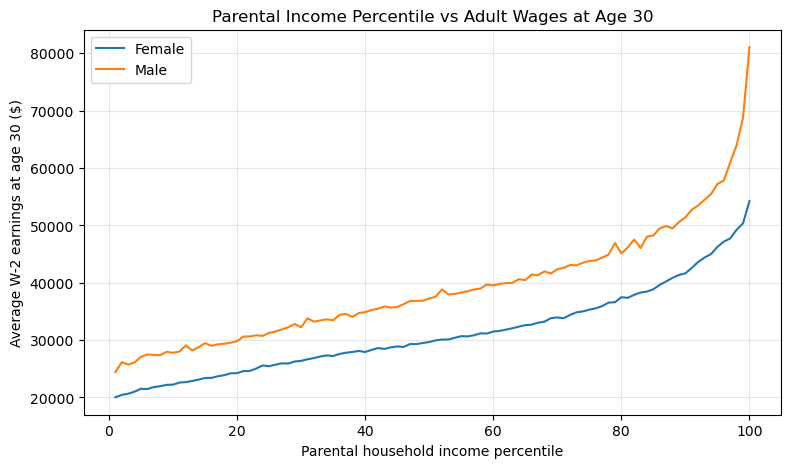

In [36]:
plt.figure(figsize=(9, 5))

sns.lineplot(
    data=oi,
    x="par_pctile",
    y="w2wages_30_f",
    label="Female"
)

sns.lineplot(
    data=oi,
    x="par_pctile",
    y="w2wages_30_m",
    label="Male"
)

plt.title("Parental Income Percentile vs Adult Wages at Age 30")
plt.xlabel("Parental household income percentile")
plt.ylabel("Average W-2 earnings at age 30 ($)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Opportunity Insights: Parental Income and Adult Wages

This graph compares parental income percentile with adult
wages at age 30 for males and females.

**So what?**
This helps us understand how family economic background
is associated with earnings later in life.

**Expected or unexpected?**
We expect individuals from higher-income families to
generally have higher earnings as adults. The graph
will help us determine whether this pattern appears
in the data.

**What next?**
We can compare these results with employment patterns
in the ELS datasets and with our primary datasets.

### Opportunity Insights: Parental Income vs. Adult Wages

The graph shows a positive relationship between parental income and adult wages at age 30. As parental income percentile increases, adult wages generally increase for both men and women. Men also consistently have higher wages than women, with the gap becoming larger at higher parental income percentiles.

**So what?** This suggests that family income is associated with economic outcomes later in life. Even though wages increase for both groups, the difference between men and women shows that gender may also play a role in adult earnings.

**Expected or unexpected?** I expected people from higher-income families to have higher wages as adults, but I was surprised by how sharply wages increased at the highest parental income percentiles, especially for men.

**What next?** We could compare these findings with our primary datasets to see whether they show similar relationships between family background and adult earnings. We could also investigate whether education helps explain some of these differences.

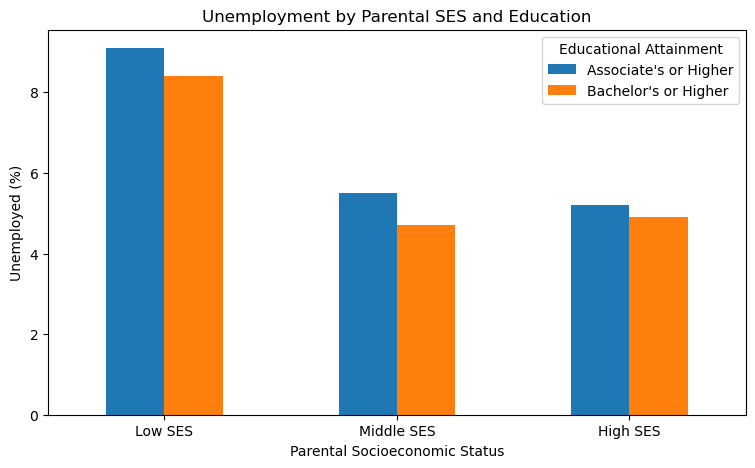

In [37]:
# Select unemployment row
a_unemployed = els_a_clean[
    els_a_clean["Employment Status"] == "Unemployed"
].iloc[0]

b_unemployed = els_b_clean[
    els_b_clean["Employment Status"] == "Unemployed"
].iloc[0]

ses = ["Low SES", "Middle SES", "High SES"]

comparison = pd.DataFrame({
    "Parent SES": ses,
    "Associate's or Higher": [a_unemployed[s] for s in ses],
    "Bachelor's or Higher": [b_unemployed[s] for s in ses]
})

comparison.plot(
    x="Parent SES",
    kind="bar",
    figsize=(9, 5)
)

plt.title("Unemployment by Parental SES and Education")
plt.xlabel("Parental Socioeconomic Status")
plt.ylabel("Unemployed (%)")
plt.xticks(rotation=0)
plt.legend(title="Educational Attainment")
plt.show()

### ELS: Unemployment by Parental SES and Education

The graph compares unemployment percentages across three parental socioeconomic groups for people with an associate's degree or higher and those with a bachelor's degree or higher.

The low-SES group has the highest unemployment percentage in both education categories. For example, among people with a bachelor's degree or higher, unemployment is 8.4% for the low-SES group compared to 4.9% for the high-SES group. The differences between the middle- and high-SES groups are much smaller.

**So what?** This suggests that family socioeconomic background may still be associated with employment outcomes even among people who have completed higher education.

**Expected or unexpected?** I expected unemployment to be lower among people with higher educational attainment, but I found it interesting that the low-SES group still had noticeably higher unemployment in both categories.

**What next?** We could compare these findings with our primary datasets to see whether parental socioeconomic status has a similar relationship with employment. We could also investigate whether other factors, such as educational attainment or demographic characteristics, help explain these differences.


In [38]:
for name, df in [
    ("ELS A", els_a_clean),
    ("ELS B", els_b_clean),
    ("Opportunity Insights", oi)
]:
    print(f"\n{name}")
    print("Shape:", df.shape)

    print("\nMissing values:")
    print(df.isnull().sum().to_string())

    print("\nDuplicate rows:", df.duplicated().sum())

    print("\nSummary statistics:")
    display(df.describe(include="all"))


ELS A
Shape: (5, 4)

Missing values:
Employment Status    0
Low SES              1
Middle SES           1
High SES             1

Duplicate rows: 0

Summary statistics:


,Employment Status,Low SES,Middle SES,High SES
count,5,4.000000,4.000000,4.000000
unique,5,NaN,NaN,NaN
top,Unemployed,NaN,NaN,NaN
freq,1,NaN,NaN,NaN
mean,NaN,25.000000,25.000000,24.975000
std,NaN,32.577395,35.751643,34.363583
min,NaN,4.500000,4.300000,5.200000
25%,NaN,7.950000,5.200000,6.850000
50%,NaN,10.950000,8.650000,9.150000
75%,NaN,28.000000,28.450000,27.275000



ELS B
Shape: (5, 4)

Missing values:
Employment Status    0
Low SES              1
Middle SES           1
High SES             1

Duplicate rows: 0

Summary statistics:


,Employment Status,Low SES,Middle SES,High SES
count,5,4.000000,4.00000,4.000000
unique,5,NaN,NaN,NaN
top,Unemployed,NaN,NaN,NaN
freq,1,NaN,NaN,NaN
mean,NaN,25.000000,25.00000,25.000000
std,NaN,34.089295,36.86968,34.875302
min,NaN,4.800000,4.10000,4.900000
25%,NaN,7.500000,4.55000,6.775000
50%,NaN,9.600000,7.90000,8.950000
75%,NaN,27.100000,28.35000,27.175000



Opportunity Insights
Shape: (100, 25)

Missing values:
par_pctile             0
w2_or_sc_nz_30_f       0
w2_or_sc_nz_30_m       0
w2_pos_30_f            0
w2_pos_30_m            0
w2_or_sc_nz_30_f_sp    0
w2_or_sc_nz_30_m_sp    0
w2_pos_30_f_sp         0
w2_pos_30_m_sp         0
w2_or_sc_nz_30_f_tp    0
w2_or_sc_nz_30_m_tp    0
w2_pos_30_f_tp         0
w2_pos_30_m_tp         0
w2_nonemp_f            0
w2_nonemp_m            0
coll1823_f             0
coll1823_m             0
kid_indv_rank_26_f     0
kid_indv_rank_26_m     0
kid_indv_rank_30_f     0
kid_indv_rank_30_m     0
kid_rank_30_f          0
kid_rank_30_m          0
w2wages_30_f           0
w2wages_30_m           0

Duplicate rows: 0

Summary statistics:


,par_pctile,w2_or_sc_nz_30_f,w2_or_sc_nz_30_m,w2_pos_30_f,w2_pos_30_m,w2_or_sc_nz_30_f_sp,w2_or_sc_nz_30_m_sp,w2_pos_30_f_sp,w2_pos_30_m_sp,w2_or_sc_nz_30_f_tp,...,coll1823_f,coll1823_m,kid_indv_rank_26_f,kid_indv_rank_26_m,kid_indv_rank_30_f,kid_indv_rank_30_m,kid_rank_30_f,kid_rank_30_m,w2wages_30_f,w2wages_30_m
count,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,...,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000
mean,50.500000,0.827979,0.833813,0.779421,0.801460,0.825741,0.799269,0.779602,0.769002,0.823241,...,0.736535,0.616320,0.481571,0.518886,0.472440,0.528164,0.517690,0.483509,31211.763414,39048.858804
std,29.011492,0.039772,0.068046,0.045622,0.070644,0.031709,0.057302,0.037180,0.057187,0.045475,...,0.154494,0.196401,0.074175,0.077840,0.072758,0.089186,0.097243,0.094696,7570.090145,10086.738256
min,1.000000,0.701873,0.619219,0.634008,0.581318,0.703665,0.601713,0.635264,0.566462,0.694450,...,0.438878,0.291378,0.332737,0.331721,0.331520,0.328640,0.320086,0.282094,20034.866784,24414.304218
25%,25.750000,0.803876,0.788567,0.753064,0.755430,0.811278,0.763895,0.765286,0.737318,0.790389,...,0.611006,0.447357,0.423572,0.457219,0.418153,0.456467,0.438290,0.405872,25681.466709,31441.570326
50%,50.500000,0.830862,0.856743,0.784345,0.825008,0.835973,0.818238,0.793787,0.787581,0.828595,...,0.741247,0.607624,0.477816,0.535983,0.464557,0.538782,0.522200,0.493917,29802.483527,37408.954874
75%,75.250000,0.861266,0.890474,0.817354,0.861294,0.845916,0.843502,0.805431,0.809855,0.861906,...,0.873517,0.782540,0.541842,0.587663,0.526576,0.602530,0.597736,0.561321,35364.066829,43821.797094
max,100.000000,0.883353,0.906234,0.842484,0.875843,0.877086,0.868762,0.831563,0.837887,0.884689,...,0.969784,0.954586,0.614812,0.631311,0.615525,0.678782,0.681686,0.648746,54231.843767,81073.710454


In [39]:
print("ELS A missing rows:")
display(els_a_clean[els_a_clean.isnull().any(axis=1)])

print("ELS B missing rows:")
display(els_b_clean[els_b_clean.isnull().any(axis=1)])

ELS A missing rows:


,Employment Status,Low SES,Middle SES,High SES
4,Source: Education Longitudinal Study of 2002 (...,NaN,NaN,NaN


ELS B missing rows:


,Employment Status,Low SES,Middle SES,High SES
4,Source: Education Longitudinal Study of 2002 (...,NaN,NaN,NaN


In [40]:
# Remove source citation rows
els_a_clean = els_a_clean[
    ~els_a_clean["Employment Status"].str.startswith("Source:", na=False)
].reset_index(drop=True)

els_b_clean = els_b_clean[
    ~els_b_clean["Employment Status"].str.startswith("Source:", na=False)
].reset_index(drop=True)

# Check results
print("ELS A:")
display(els_a_clean)

print("\nELS B:")
display(els_b_clean)

print("\nMissing values:")
print(els_a_clean.isnull().sum())
print(els_b_clean.isnull().sum())

ELS A:


,Employment Status,Low SES,Middle SES,High SES
0,Unemployed,9.1,5.5,5.2
1,Out-of-the-labor force,4.5,4.3,7.4
2,Working 0-34 hours/week,12.8,11.8,10.9
3,Working 35+ hours/week,73.6,78.4,76.4



ELS B:


,Employment Status,Low SES,Middle SES,High SES
0,Unemployed,8.4,4.7,4.9
1,Out-of-the-labor force,4.8,4.1,7.4
2,Working 0-34 hours/week,10.8,11.1,10.5
3,Working 35+ hours/week,76.0,80.1,77.2



Missing values:
Employment Status    0
Low SES              0
Middle SES           0
High SES             0
dtype: int64
Employment Status    0
Low SES              0
Middle SES           0
High SES             0
dtype: int64


### ELS Data Cleaning and Anomalies

Both ELS datasets initially appeared to have three missing values, one in each parental SES column. After checking the rows, I found that these missing values came from a source citation at the bottom of each table rather than actual employment data.

I removed the source rows because they weren't part of the observations being analyzed. After cleaning, both datasets contained four employment categories and three parental SES groups, with no missing values or duplicates.

The employment values are percentages, and the tables contain aggregated group statistics rather than individual student records.

In [41]:
for name, df in [
    ("ELS A", els_a_clean),
    ("ELS B", els_b_clean)
]:
    print(f"\n{name} percentage totals:")
    print(df[["Low SES", "Middle SES", "High SES"]].sum())


ELS A percentage totals:
Low SES       100.0
Middle SES    100.0
High SES       99.9
dtype: float64

ELS B percentage totals:
Low SES       100.0
Middle SES    100.0
High SES      100.0
dtype: float64


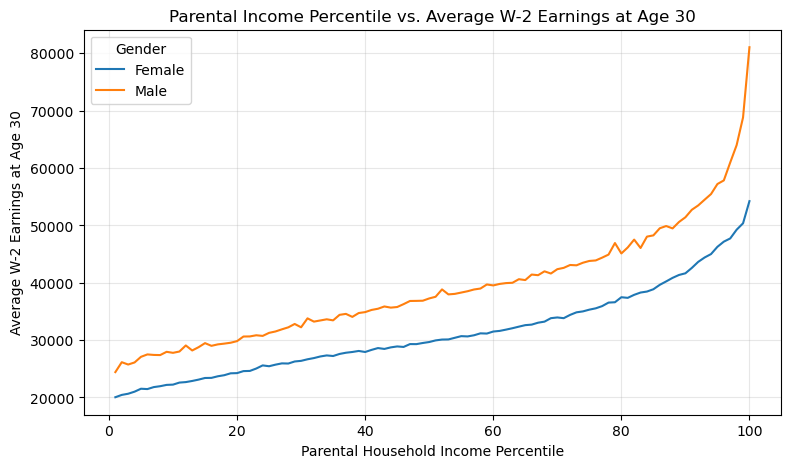

In [42]:
plt.figure(figsize=(9, 5))

sns.lineplot(
    data=oi,
    x="par_pctile",
    y="w2wages_30_f",
    label="Female"
)

sns.lineplot(
    data=oi,
    x="par_pctile",
    y="w2wages_30_m",
    label="Male"
)

plt.title("Parental Income Percentile vs. Average W-2 Earnings at Age 30")
plt.xlabel("Parental Household Income Percentile")
plt.ylabel("Average W-2 Earnings at Age 30")
plt.legend(title="Gender")
plt.grid(alpha=0.3)

plt.show()

### Opportunity Insights Data Quality

The Opportunity Insights dataset contains 100 rows and 25 columns, with each row representing a parental income percentile rather than an individual person.

I checked the parental income percentile and adult wage variables used in my graph. There were no missing values, duplicate parental income percentiles, or negative wages. The parental income percentiles also ranged from 1 to 100 as expected.

I didn't find any issues that required cleaning for these variables, so I kept the original values for the analysis.

### Opportunity Insights: Parental Income and Adult Earnings

The graph shows that average W-2 earnings at age 30 generally increase as parental household income percentile increases. This pattern appears for both men and women, although men consistently have higher average earnings. The increase is especially noticeable at the highest parental income percentiles.

**So what?** This suggests that family economic background is associated with earnings later in life. It also shows differences between men and women, which could be worth investigating further.

**Expected or unexpected?** I expected people from higher-income families to have higher earnings as adults, but I was surprised by how sharply earnings increased near the highest parental income percentiles.

**What next?** I would compare this pattern with our primary datasets to see whether they show similar relationships between family background and adult economic outcomes. I would also look into how education and employment might help explain these differences.

### Connection to Our Research Question

Our project's main research question is how strongly early childhood family income and parental education levels predict adult earnings and employment status.

The Opportunity Insights dataset helps us explore the income portion of this question. Our graph shows that average W-2 earnings at age 30 generally increase as parental household income percentile increases. This suggests that family income is associated with adult earnings.

The ELS dataset adds another perspective by looking at employment outcomes across parental socioeconomic groups. We found that the low-SES group had higher unemployment percentages than the middle- and high-SES groups, even among people with postsecondary degrees.

These findings are relevant to our primary PSID and NLSY97 analyses because they examine similar relationships between family background and adult outcomes. However, the secondary datasets use aggregated statistics rather than individual records, so we cannot directly compare their values with individual-level survey observations.

The next step is to compare these patterns with the relationships identified in PSID and NLSY97 to see whether the findings are consistent across datasets.

### Consistency With Our Data Acquisition Plan

Our analysis follows the overall data acquisition plan because we used Opportunity Insights and ELS as secondary datasets to support our research on family background and adult economic outcomes.

For Opportunity Insights, we focused on parental income percentile and average W-2 earnings at age 30. For ELS, we compared unemployment percentages across parental socioeconomic groups and educational attainment categories.

We did not change our selected datasets, but we narrowed the analysis to variables that were available and relevant to our research question. These datasets provide supporting evidence rather than replacing our primary PSID and NLSY97 analyses.

### Comparison: Opportunity Insights and NLSY97

This plot compares how adult earnings change with parental household income in a secondary dataset and a primary dataset.

- **Opportunity Insights** gives average W-2 earnings at age 30 for each parental income percentile (aggregated groups, averaged here across men and women).
- **NLSY97** has individual respondents. We split respondents into 20 groups by 1996 household income and averaged their 2020 adult wages.

The two datasets measure earnings in different years, at different ages, and for different populations, and their dollar amounts are not directly comparable. The plot therefore shows each dataset's earnings relative to its own average (1.0 means average).

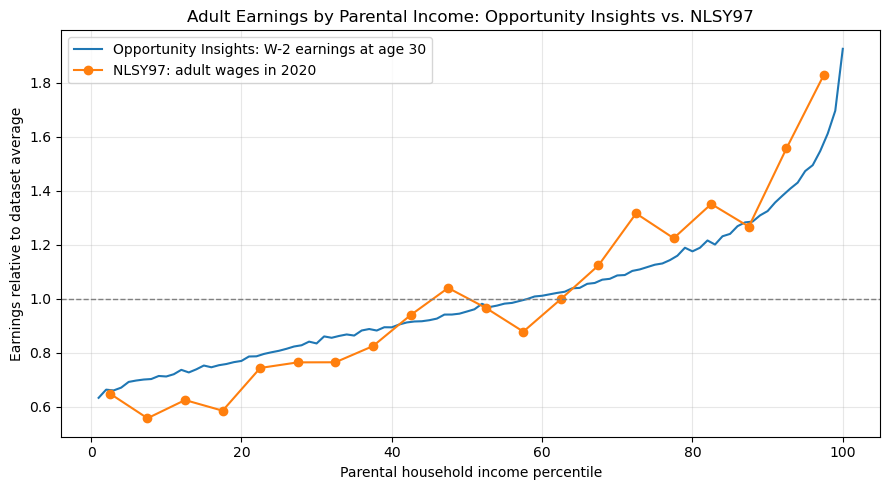

NLSY97 respondents in comparison: 4725
Lowest to highest parental income group, relative earnings
Opportunity Insights: 0.63 to 1.93
NLSY97: 0.65 to 1.83


In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

oi_curve = pd.DataFrame(
    {
        "percentile": oi["par_pctile"],
        "earnings": (oi["w2wages_30_f"] + oi["w2wages_30_m"]) / 2,
    }
).sort_values("percentile").reset_index(drop=True)
oi_curve["relative"] = oi_curve["earnings"] / oi_curve["earnings"].mean()

nlsy = (
    nlsy97_clean.select(["R1204500", "U5753500"])
    .drop_nulls()
    .to_pandas()
    .rename(columns={"R1204500": "income", "U5753500": "wages"})
)
nlsy["group"] = pd.qcut(nlsy["income"].rank(method="first"), 20, labels=False)
nlsy_curve = nlsy.groupby("group")["wages"].mean().reset_index()
nlsy_curve["percentile"] = nlsy_curve["group"] * 5 + 2.5
nlsy_curve["relative"] = nlsy_curve["wages"] / nlsy_curve["wages"].mean()

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(oi_curve["percentile"], oi_curve["relative"], label="Opportunity Insights: W-2 earnings at age 30")
ax.plot(nlsy_curve["percentile"], nlsy_curve["relative"], marker="o", label="NLSY97: adult wages in 2020")
ax.axhline(1, color="gray", linestyle="--", linewidth=1)
ax.set_title("Adult Earnings by Parental Income: Opportunity Insights vs. NLSY97")
ax.set_xlabel("Parental household income percentile")
ax.set_ylabel("Earnings relative to dataset average")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("NLSY97 respondents in comparison:", len(nlsy))
print("Lowest to highest parental income group, relative earnings")
print("Opportunity Insights:", round(oi_curve["relative"].iloc[0], 2), "to", round(oi_curve["relative"].iloc[-1], 2))
print("NLSY97:", round(nlsy_curve["relative"].iloc[0], 2), "to", round(nlsy_curve["relative"].iloc[-1], 2))


### Comparison notes: Opportunity Insights and NLSY97

**What the plot shows.** Adult earnings rise steadily with parental household income in both datasets. In Opportunity Insights, relative earnings go from 0.63 in the lowest parental income percentile to 1.93 in the highest. In NLSY97 (4,725 respondents split into 20 income groups), they go from 0.65 to 1.83.

**So what?** Two sources that measure family income and earnings differently show a similar pattern, with the highest-income group earning roughly three times as much as the lowest. This supports the idea that family income is associated with adult earnings and that the pattern is not unique to one dataset. It describes an association and does not show that family income causes the difference.

**Expected or unexpected?** The direction was expected. We did not expect the two curves to be so close in size, given how different the datasets are.

**Limits.** The datasets measure earnings in different years and at different ages, and Opportunity Insights averages men and women. NLSY97 wages include zeros for people with no job income, and its highest household incomes were adjusted for privacy. Opportunity Insights groups people by national percentile, while NLSY97 groups respondents by rank within the sample. Dollar amounts are not comparable, which is why the plot uses relative earnings.

**What next?** Check whether PSID shows the same pattern for family income and adult wages. Then see how much of the gradient parental education explains, and look more closely at the steep rise in the top income groups.

## Anomaly summary: counts and actions

Counts come from each team member's notes above. NLSY97 counts are before cleaning.

| Dataset | Feature | Anomaly | Rows affected | Action |
|---|---|---|---:|---|
| PSID | Head's education | Coded 99 (unknown) | 102 | Treated as missing |
| PSID | Spouse's education | Coded 99 (unknown) | 80 | Treated as missing |
| PSID | Wages/salary | Coded 9,999,999 (unknown) | 121 | Treated as missing |
| PSID | Wage receipt (TA210678) | Coded 9 (don't know, no answer, or refused) | 33 | Flagged only; their wage amount is coded 0, so they are not confirmed $0 earners |
| PSID | Family income | Negative value | 1 | Kept because the codebook allows business or farm losses |
| PSID | Release number, family income, head's education, spouse's education | Missing values in each column | 206 | Kept in the raw data and excluded only from comparisons that need them |
| PSID and linkage | Household identifiers | Respondents not confirmed in the recorded 1997 household | 265 | Used household income as the link |
| PSID, PSID linkage, NLSY97 | All rows | Exact duplicate rows | 0 | None removed |
| NLSY97 | Household income | Missing or skip codes | 2,396 | Replaced with nulls and kept the 3 valid negative amounts |
| NLSY97 | Father's education | Missing or skip codes | 1,856 | Replaced with nulls |
| NLSY97 | Father's education | Code 95 (ungraded) | 8 | Excluded from numeric comparisons |
| NLSY97 | Mother's education | Missing or skip codes | 688 | Replaced with nulls |
| NLSY97 | Mother's education | Code 95 (ungraded) | 6 | Excluded from numeric comparisons |
| NLSY97 | Received job income | Missing or skip codes | 2,327 | Replaced with nulls |
| NLSY97 | Wages/salary | Missing or skip codes | 3,783 | Replaced with nulls |
| NLSY97 | Wages/salary | Skipped amount for respondents with no job income | 1,162 | Set to zero |
| NLSY97 | Weeks worked | Missing or skip codes | 1,746 | Replaced with nulls |
| ELS (both files) | Parental SES columns | Apparent missing values that were source-citation rows | 3 per file | Removed the source rows |
| Opportunity Insights | Parental income percentile and adult wages | None found (100 rows, no missing, duplicate, or negative values) | 0 | No cleaning needed |
